In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
import h5py
import pickle
from scipy.integrate import simpson

In [2]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [3]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra, 
    get_realspace_profile, get_NFW_profile, comoving_distance, 
    get_cached_profile
)

##### Power Spectrum Plots

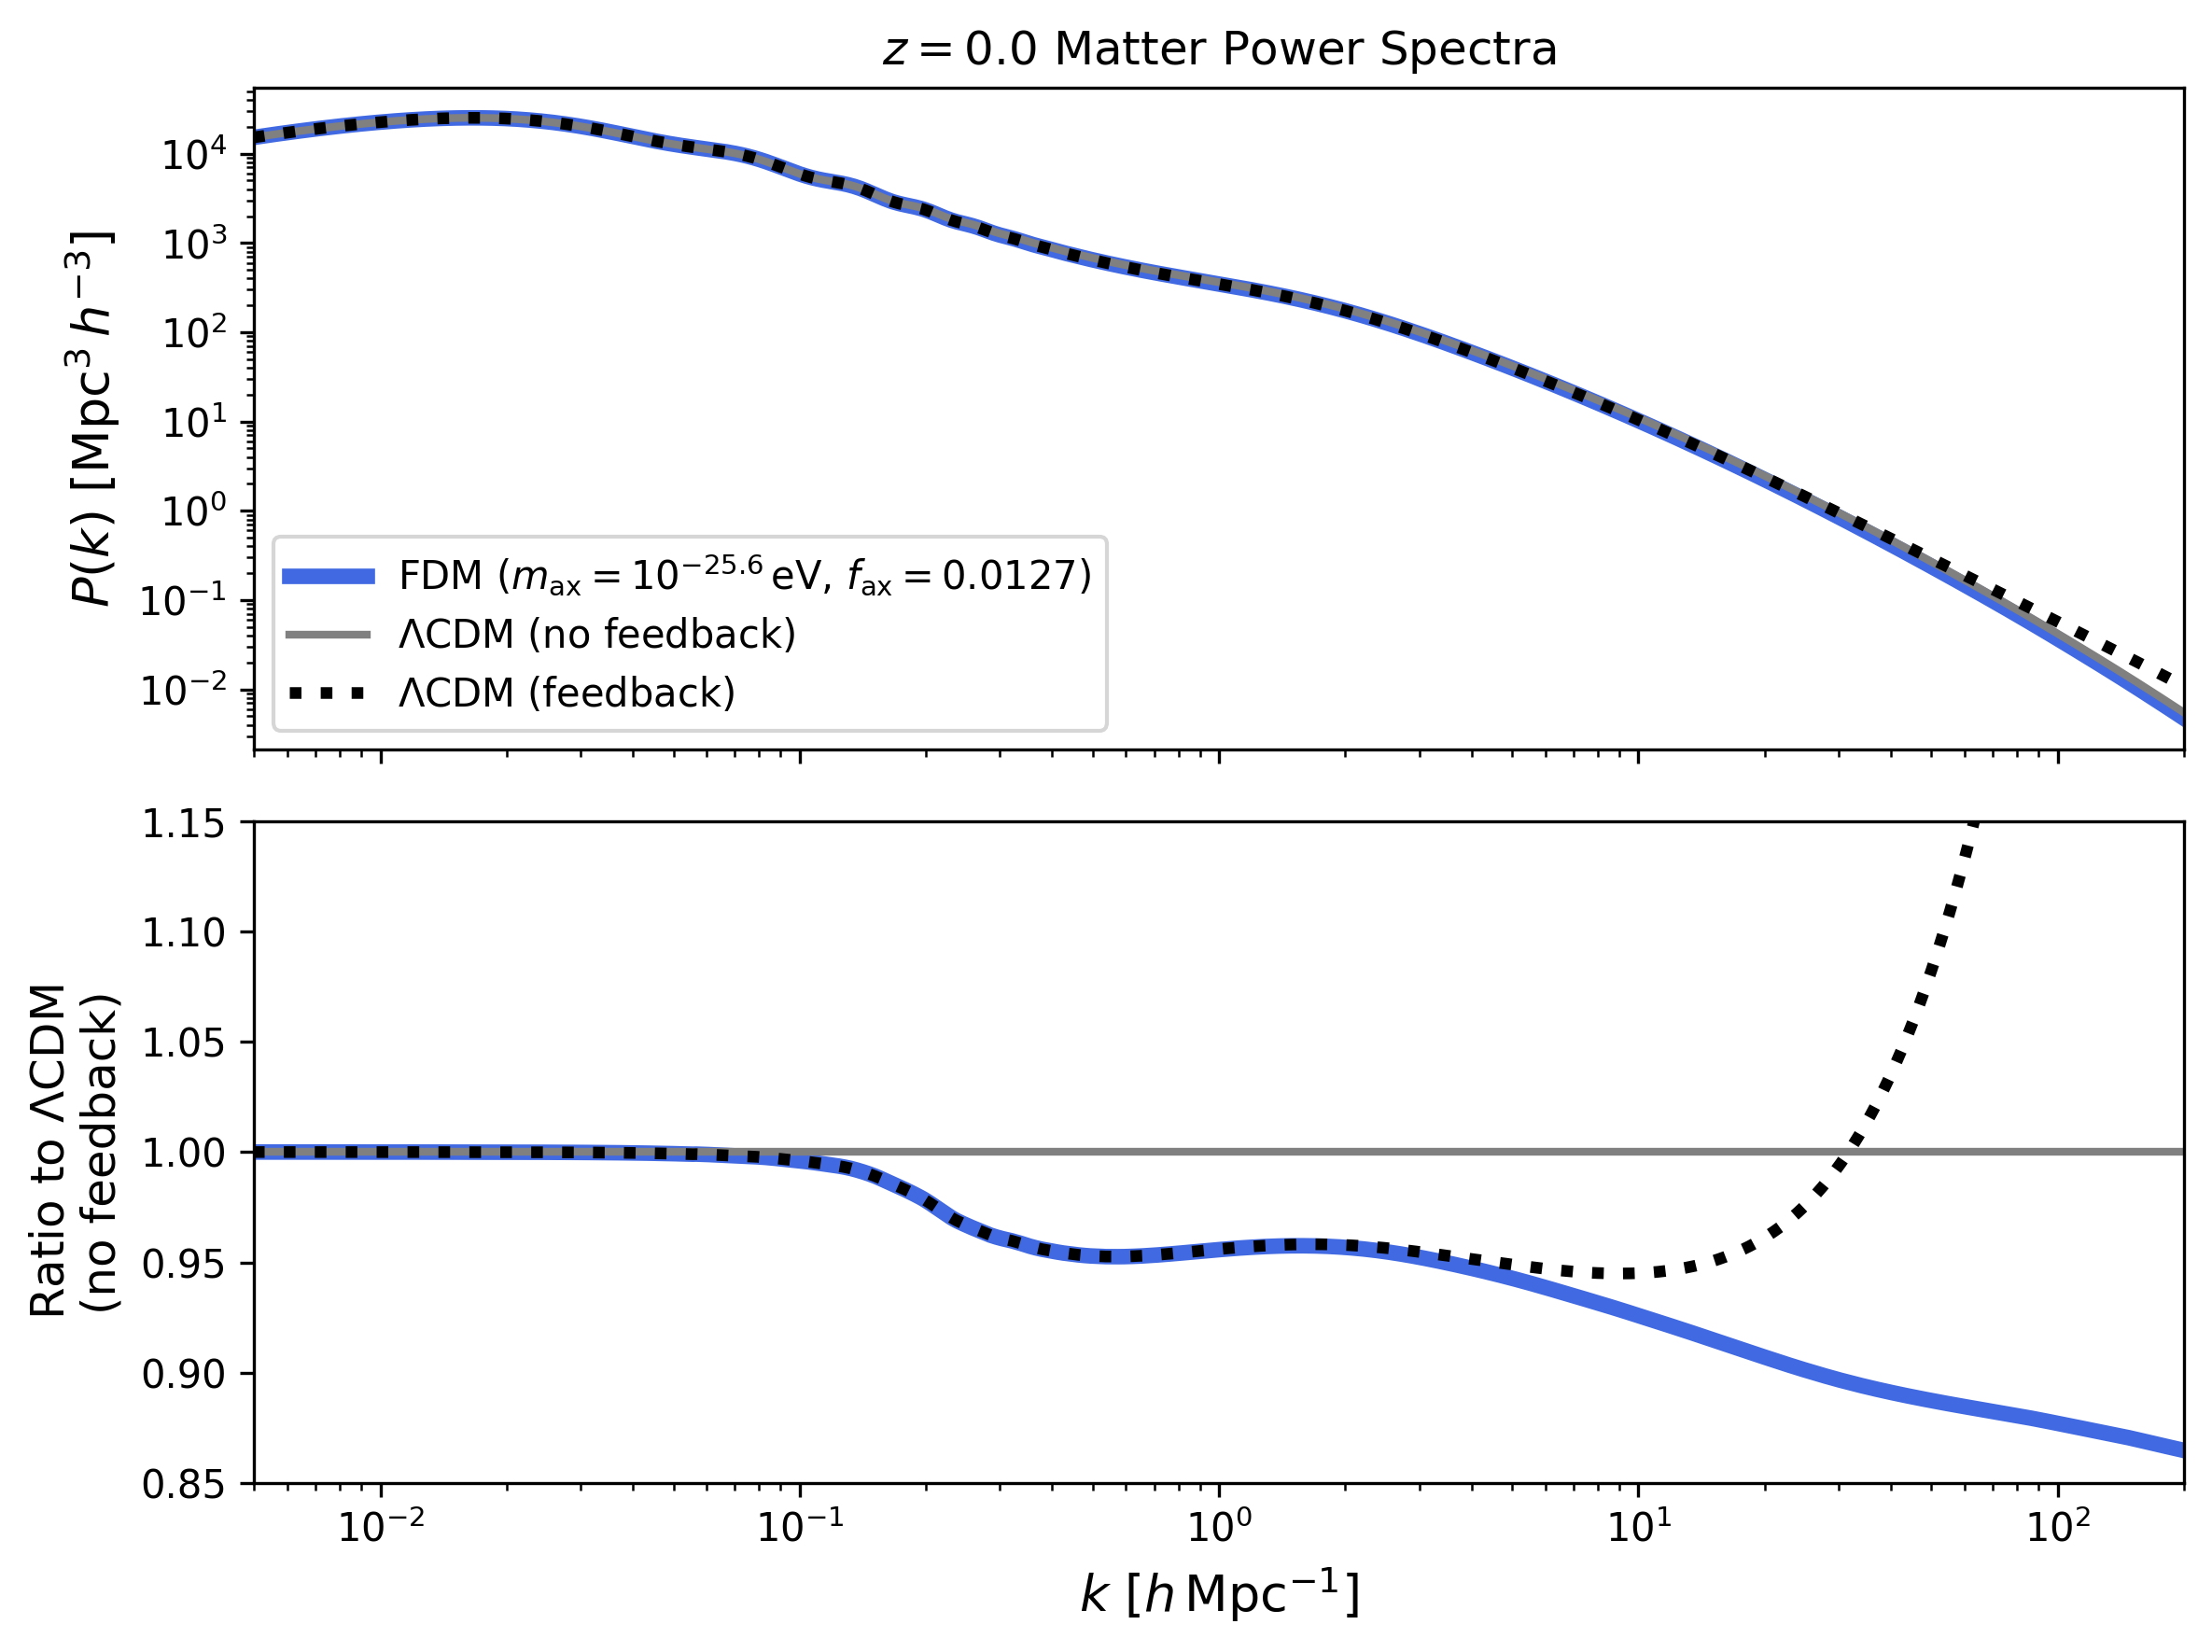

In [42]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 0.0

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to $\Lambda$CDM' + '\n(no feedback)', fontsize=12)
ax1.set_title(r'$z=0.0$ Matter Power Spectra')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()

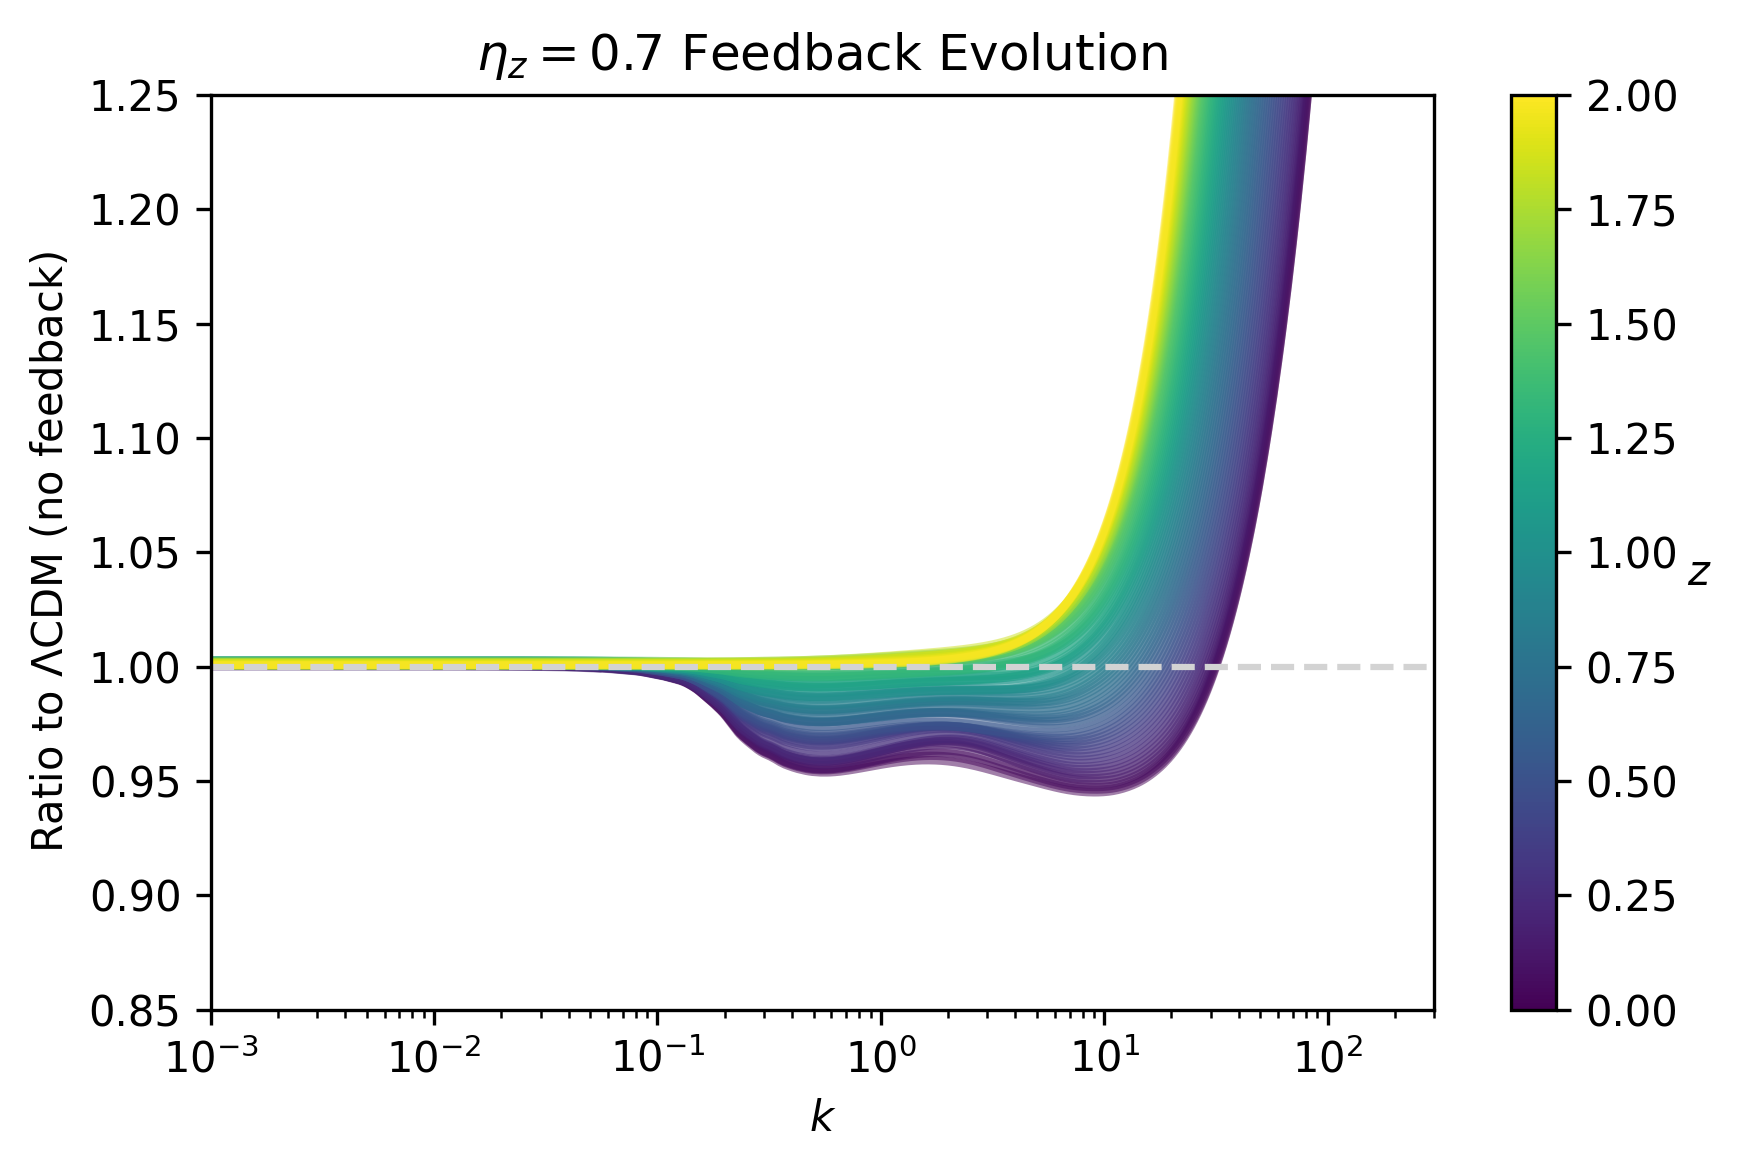

In [5]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 4), dpi=300)

gamma_val = 0.0
etaz = 0.7

K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

z_arr      = np.linspace(0.0, 2.0, 81)
#z_arr = [0.0,0.5,1.0,1.5,2.0]
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(z_arr)))

for z, color in zip(z_arr, colors):
    with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    k_arr_HMCode = data_LCDM['power_spec_dic']['k']

    feedback_model = f"etaz{etaz}_preferred_cooled"
    baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
    #baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]

    ax1.semilogx(k_arr_HMCode, baryonic_profile[-1]['P']/data_LCDM['P'], c=color, ls='-',lw=2.,alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.0, vmax=2.0))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1)
cbar.set_label(r'$z$', rotation=0, labelpad=5)

ax1.axhline(1.0, c='lightgray', ls='--')

ax1.set_xlabel(r'$k$')
ax1.set_ylabel(r'Ratio to $\Lambda$CDM (no feedback)')

ax1.set_ylim(0.85,1.25)
ax1.set_xlim(1e-3,3e2)
ax1.set_title(fr"$\eta_z = {etaz}$ Feedback Evolution")

plt.tight_layout()
plt.show()

##### Profile Plots

/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")
/tmp/ipykernel_2940391/3895193278.py:30: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
/tmp/ipykernel_2940391/3895193278.py:33: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])


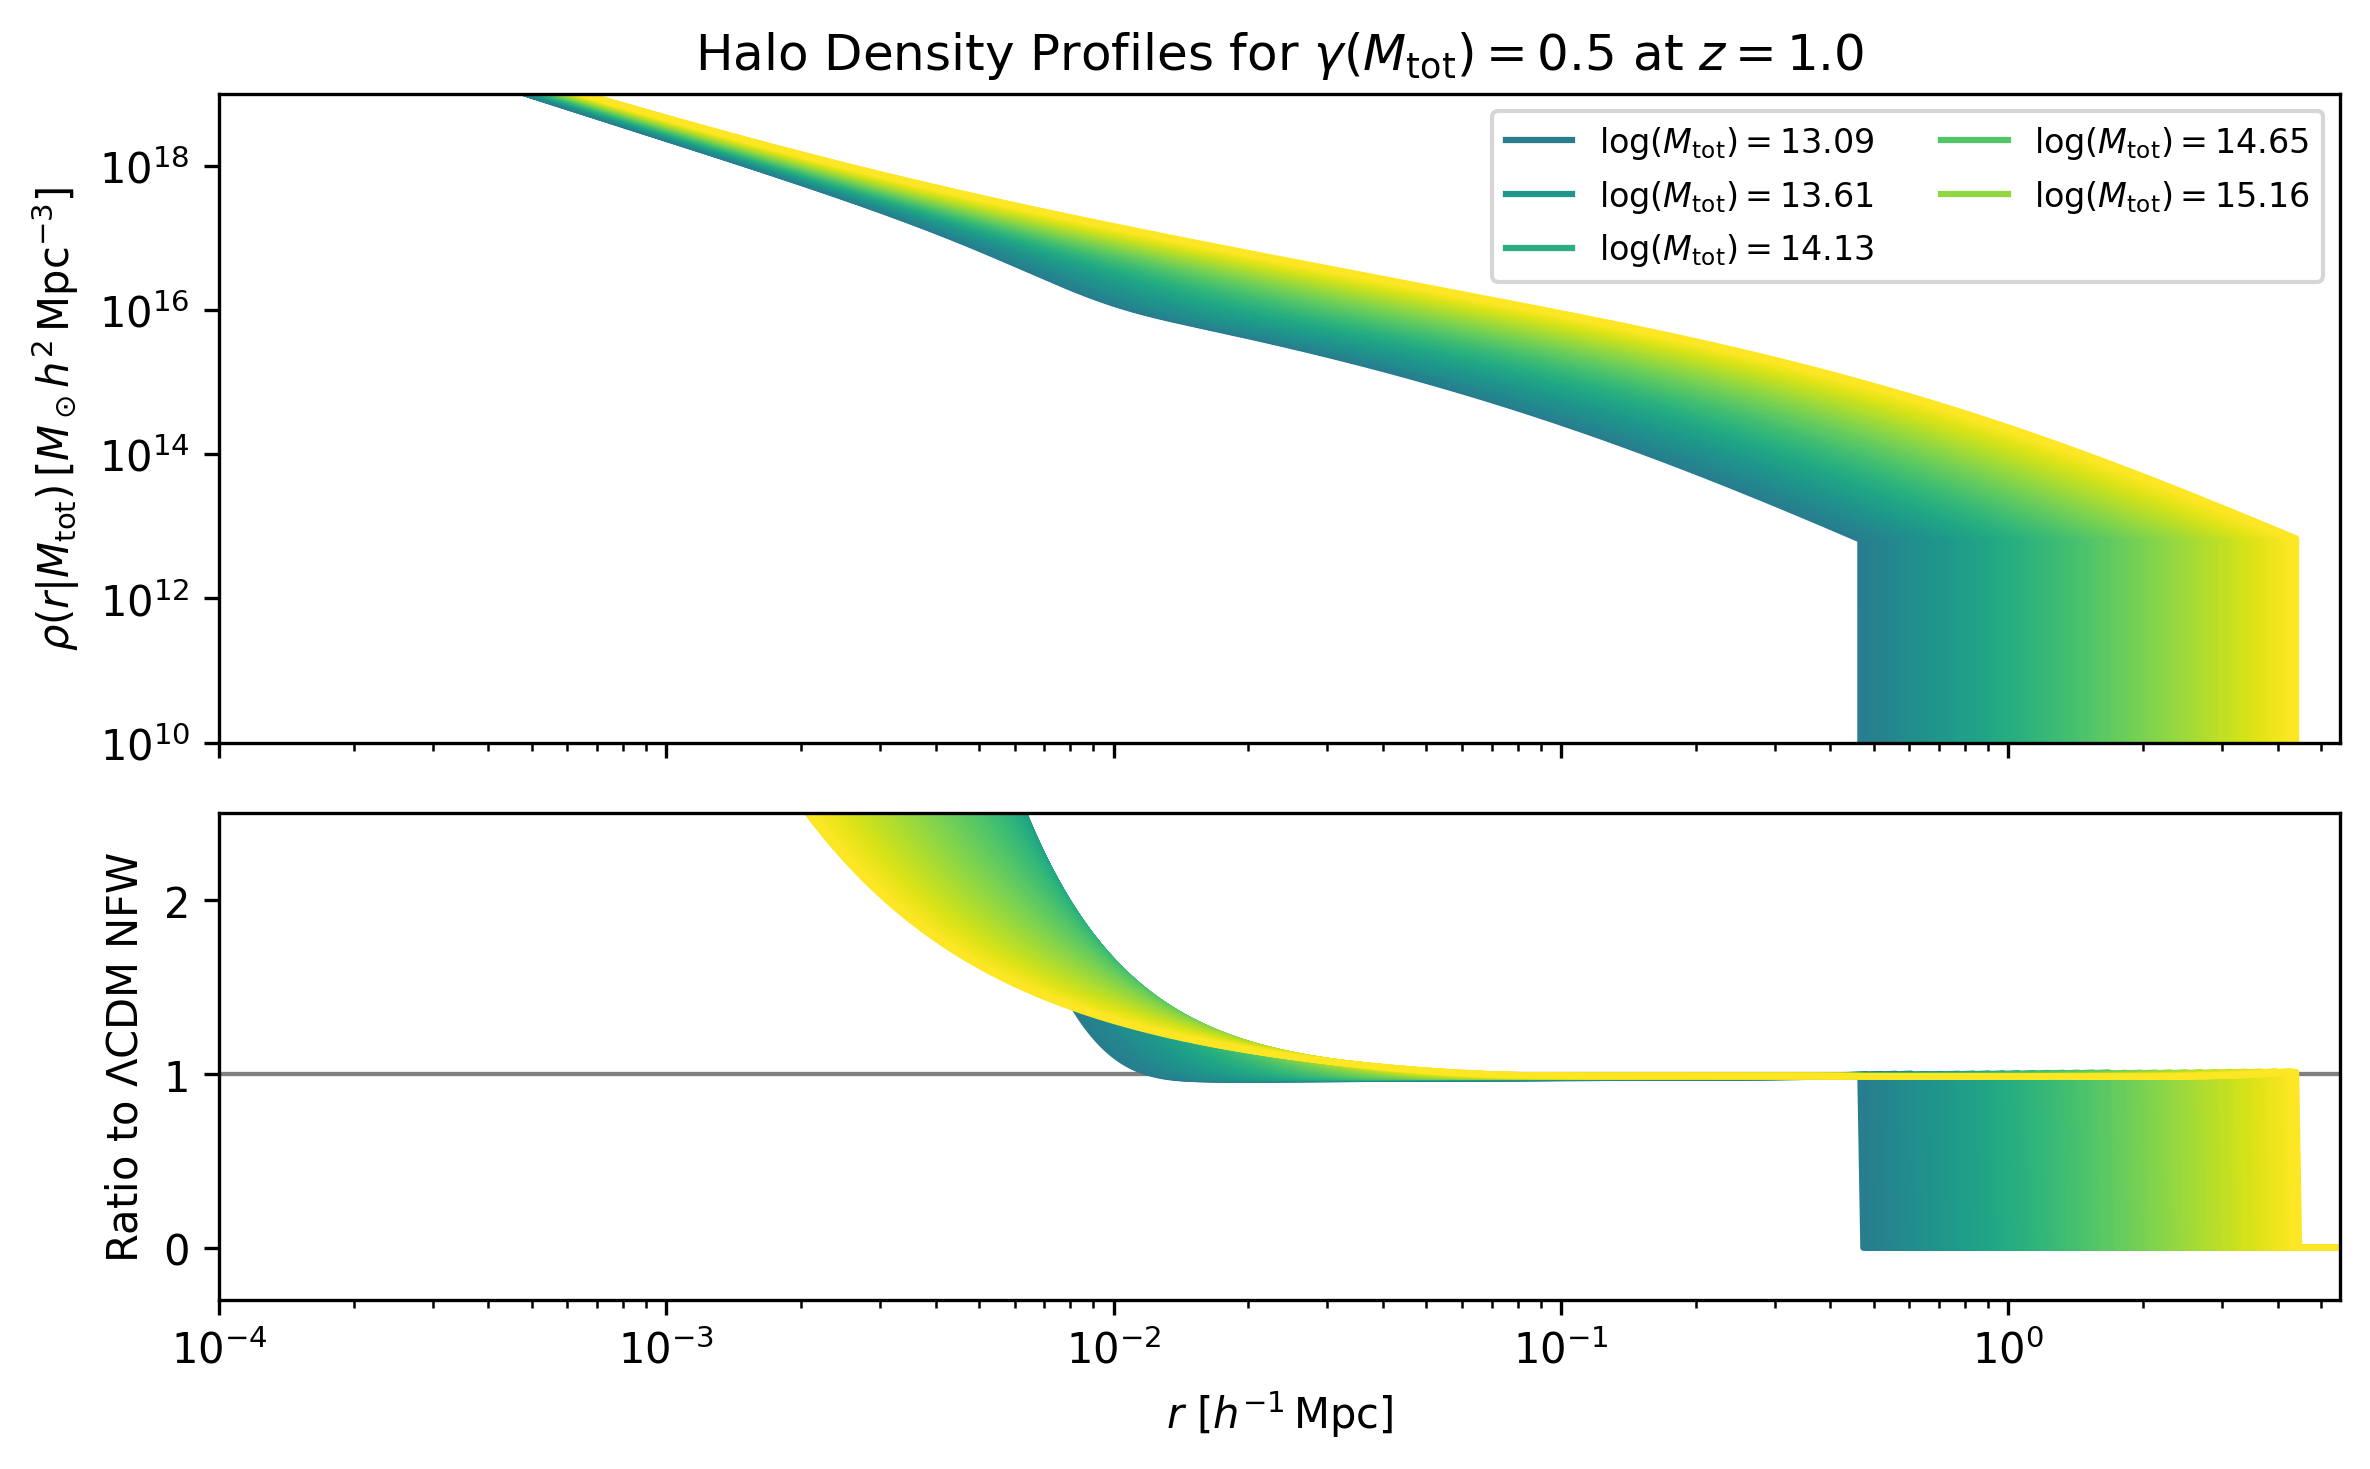

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)
k_arr = np.logspace(-6, 6, 8192)
r_arr = np.logspace(-4, np.log10(1/min(k_arr)), 1500)

gamma_val = 0.5
etaz = 0.7
z = 1.0
feedback_model = f"etaz{etaz}_preferred_cooled"
keys = np.arange(np.size(data_LCDM['M'])) # M values
keys_labels = [0,31,62,93,125,156,187,218,249] # M values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
rho_NFW = get_realspace_profile(get_NFW_profile(k_arr=k_arr, r_s=r_s, r_v=r_v, r_t=max(r_arr) * r_v/r_v), 
                                r_t=max(r_arr) * r_v/r_v, r_arr=r_arr, k_arr=k_arr, M_arr=data_LCDM['M'])

#baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
for m_index in keys[125:]:
    if m_index in keys_labels:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
    else:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])
#print(np.round(baryonic_profile[-1]['M_total_enclosed']/M_arr,4))

ax1.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
ax2.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
#ax2.set_ylim(0.5,1.5)
#ax1.set_ylim(1e12,1e19)
ax2.set_ylim(-0.3,2.5)
ax1.set_ylim(1e10,1e19)

ax2.set_ylabel(r'Ratio to $\Lambda$CDM NFW')
ax2.set_xscale("log")
ax2.set_yscale("linear")
ax1.set_yscale("log")
ax1.set_ylabel(r'$\rho(r|M_\text{tot}) \, [M_\odot h^2\,\text{Mpc}^{-3} ]$')
ax2.set_xlabel(r'$r$ $[h^{-1}\,\text{Mpc}]$')

ax1.set_title(rf'Halo Density Profiles for $\gamma(M_\text{{tot}}) = {gamma_val}$ at $z={z}$')
ax1.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

##### Cluster Counts Plot

LCDM_hat0.0: N_sel=23663
LCDM_hat0.5: N_sel=24148
LCDM_hat1.0: N_sel=24359
LCDM: N_sel=26303
FDM_preferred: N_sel=25300


/tmp/ipykernel_363585/3617513077.py:393: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


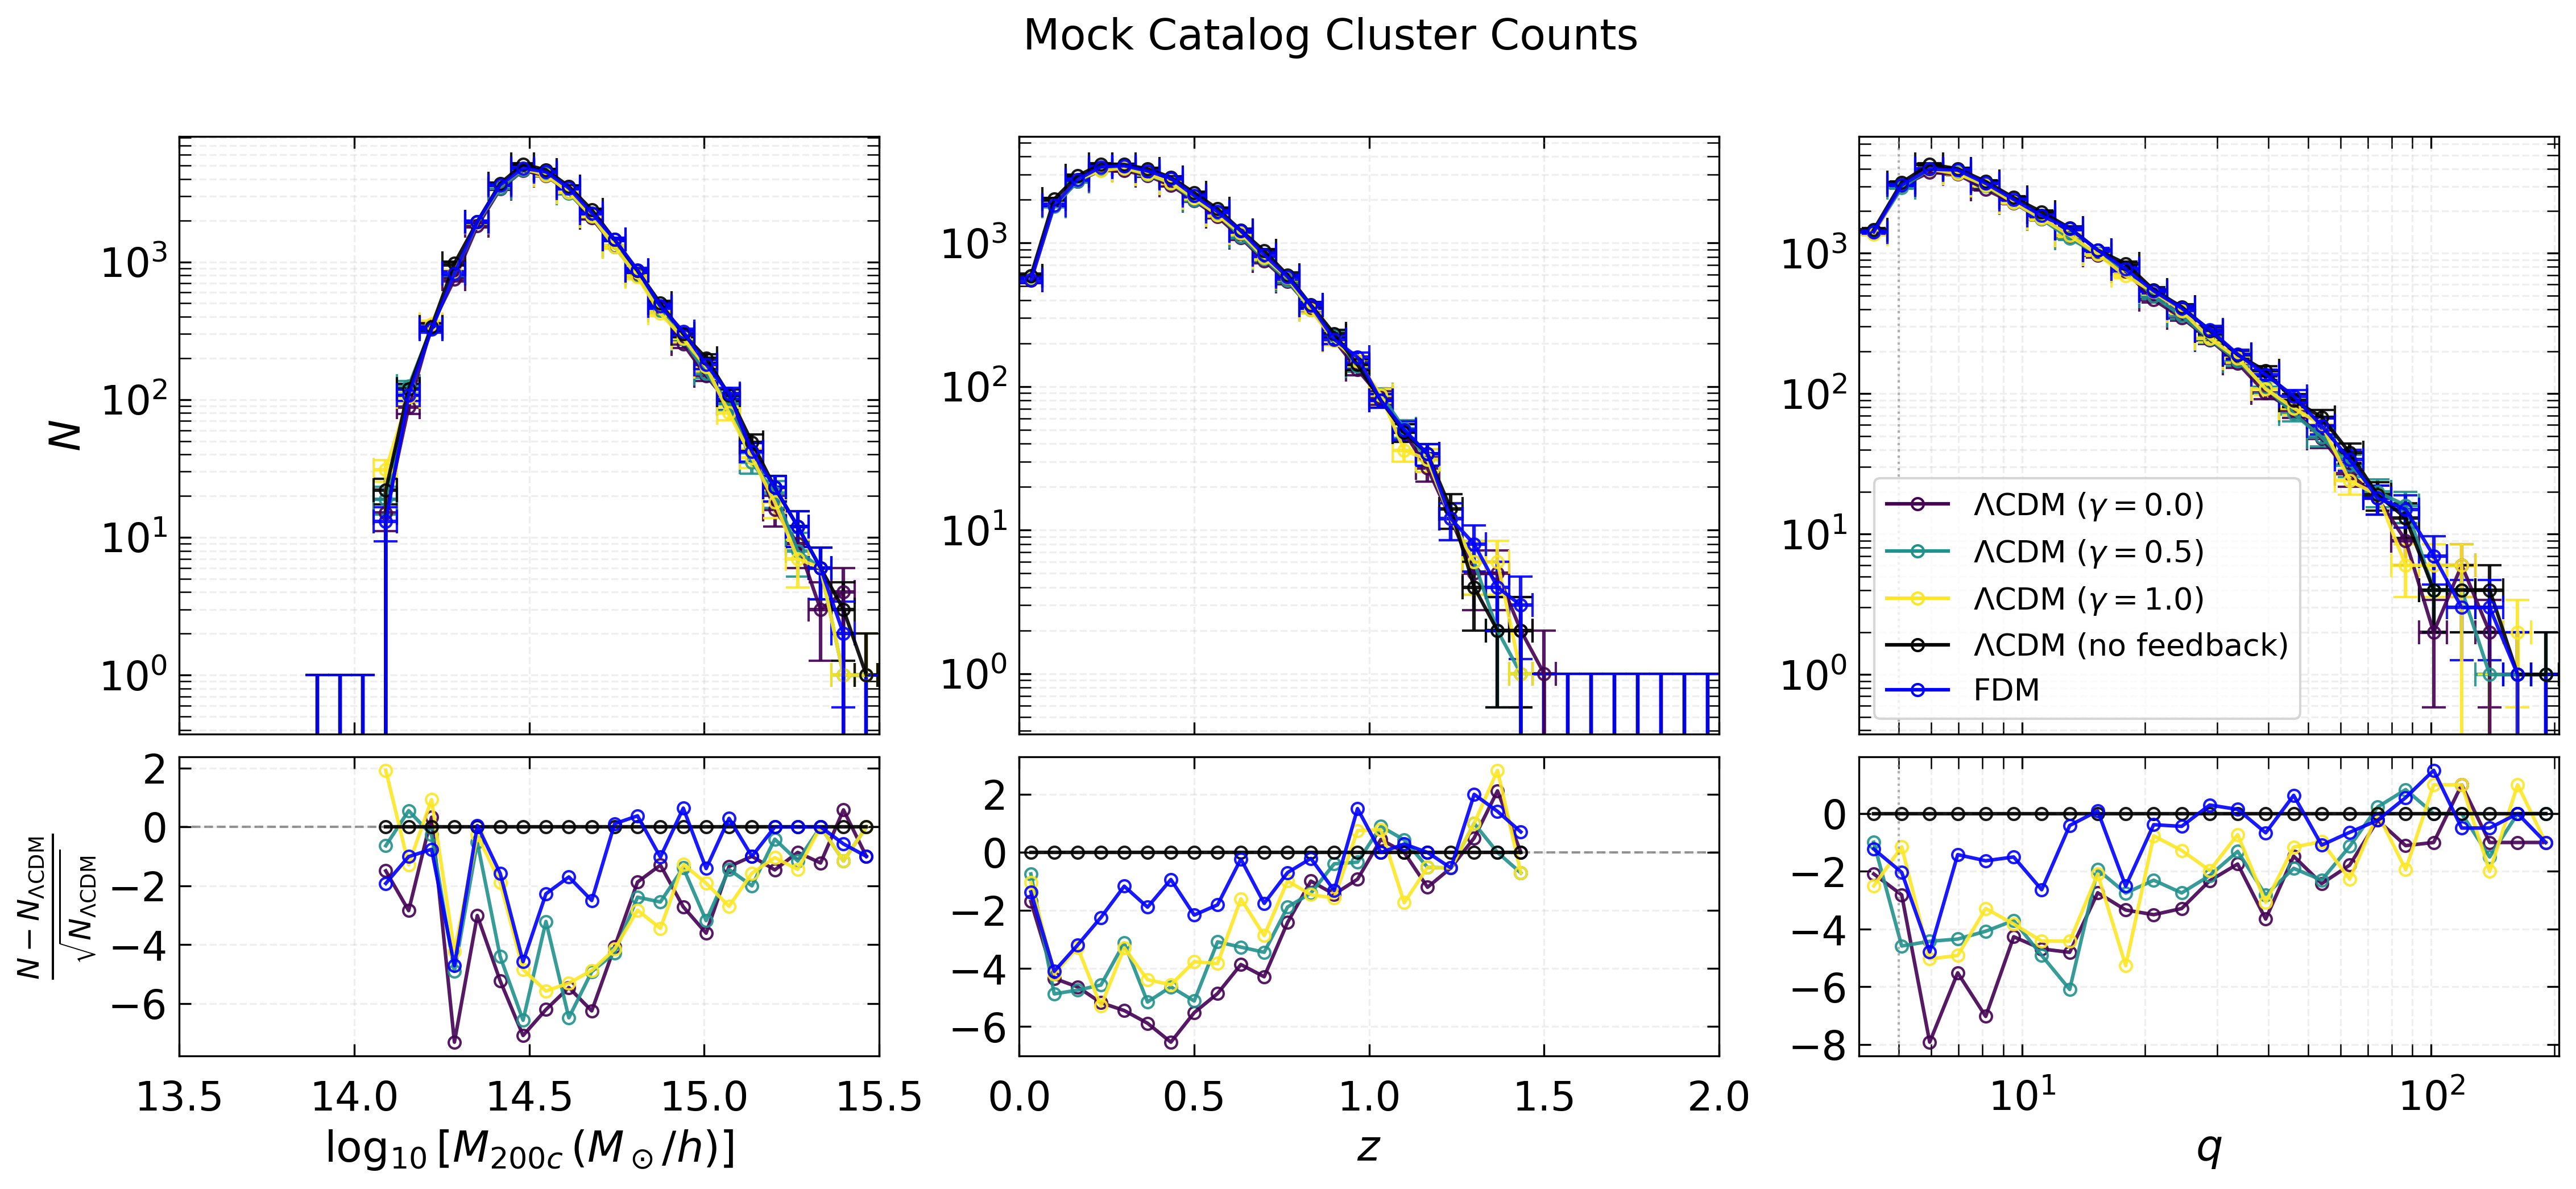

In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

%matplotlib inline

# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

CATALOG_DIR = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
SEED = 42

keys = [0.0,0.5,1.0] # gamma values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))
HMF_TYPES = [
    'LCDM_hat0.0',
    'LCDM_hat0.5',
    'LCDM_hat1.0',
    'LCDM',
    'FDM_preferred',
]

COLORS = [
    color_dict[0.0],
    color_dict[0.5],
    color_dict[1.0],
    'k',
    'b',
]

LABELS = [
    r'$\Lambda$CDM ($\gamma=0.0$)',
    r'$\Lambda$CDM ($\gamma=0.5$)',
    r'$\Lambda$CDM ($\gamma=1.0$)',
    r'$\Lambda$CDM (no feedback)',
    r'FDM',
]

N_BINS_M = 25
N_BINS_Z = 30
N_BINS_Q = 25

label_size = 17
title_size = 18
legend_size = 13

q_type = 'q_true'

# ──────────────────────────────────────────────────────────────────────────────
# STYLING
# ──────────────────────────────────────────────────────────────────────────────

def style_ax(ax):

    ax.tick_params(
        axis='x',
        which='both',
        length=5,
        direction='in',
        pad=10
    )

    ax.tick_params(
        axis='y',
        which='both',
        length=5,
        direction='in',
        pad=5
    )

    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

    plt.setp(
        ax.get_yticklabels(),
        rotation='horizontal',
        fontsize=label_size
    )

    plt.setp(
        ax.get_xticklabels(),
        fontsize=label_size
    )

    ax.grid(
        visible=True,
        which='both',
        alpha=0.2,
        linestyle='--'
    )


# ──────────────────────────────────────────────────────────────────────────────
# LOAD CATALOGS
# ──────────────────────────────────────────────────────────────────────────────

cats = {}

for hmf_type in HMF_TYPES:

    path = (
        f"{CATALOG_DIR}/"
        f"{hmf_type.replace('.', 'p')}_mock_seed{SEED}.pkl"
    )

    with open(path, "rb") as f:
        cats[hmf_type] = pickle.load(f)

    print(f"{hmf_type}: N_sel={cats[hmf_type]['n_selected']}")

# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────

ref = cats['LCDM']

M_edges = np.logspace(
    np.log10(ref['M200c_true'].min() * 0.6),
    np.log10(ref['M200c_true'].max() * 1.1),
    N_BINS_M + 1
)

z_edges = np.linspace(
    0.0,
    2.0,
    N_BINS_Z + 1
)

q_edges = np.logspace(
    np.log10(ref['Q_TH'] * 0.8),
    np.log10(ref[q_type].max() * 1.1),
    N_BINS_Q + 1
)

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

# plotting coordinates

M_x = np.log10(M_centres)
z_x = z_centres
q_x = q_centres

# ──────────────────────────────────────────────────────────────────────────────
# HORIZONTAL BIN-WIDTH ERRORS
# ──────────────────────────────────────────────────────────────────────────────

M_xerr = np.vstack([
    M_x - np.log10(M_edges[:-1]),
    np.log10(M_edges[1:]) - M_x
])

z_xerr = np.vstack([
    z_x - z_edges[:-1],
    z_edges[1:] - z_x
])

q_xerr = np.vstack([
    q_x - q_edges[:-1],
    q_edges[1:] - q_x
])

# ──────────────────────────────────────────────────────────────────────────────
# HISTOGRAMS
# ──────────────────────────────────────────────────────────────────────────────

counts = {}

for hmf_type in HMF_TYPES:

    c = cats[hmf_type]

    counts[hmf_type] = {
        'M': np.histogram(c['M200c_true'], bins=M_edges)[0].astype(float),
        'z': np.histogram(c['z'], bins=z_edges)[0].astype(float),
        'q': np.histogram(c[q_type], bins=q_edges)[0].astype(float),
    }

n_lcdm = counts['LCDM']

# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 7),
    dpi=300,
    gridspec_kw={
        'height_ratios': [1, 0.5],
        'hspace': 0.05,
    }
)

(ax_M, ax_z, ax_q), (ax_dM, ax_dz, ax_dq) = axes

top_axes = [ax_M, ax_z, ax_q]
bot_axes = [ax_dM, ax_dz, ax_dq]

# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────

for hmf_type, color, label in zip(HMF_TYPES, COLORS, LABELS):

    n = counts[hmf_type]

    # -------------------------------------------------------------------------
    # TOP ROW
    # -------------------------------------------------------------------------

    for ax, vals, x, xerr in [

        (ax_M, n['M'], M_x, M_xerr),
        (ax_z, n['z'], z_x, z_xerr),
        (ax_q, n['q'], q_x, q_xerr),

    ]:

        ax.errorbar(
            x,
            vals,
            xerr=xerr,
            yerr=np.sqrt(np.maximum(vals, 1)),
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            capsize=5,
            color=color,
            alpha=0.9,
            label=label
        )

    # -------------------------------------------------------------------------
    # BOTTOM ROW
    # -------------------------------------------------------------------------

    for ax, vals, ref_vals, x in [

        (ax_dM, n['M'], n_lcdm['M'], M_x),
        (ax_dz, n['z'], n_lcdm['z'], z_x),
        (ax_dq, n['q'], n_lcdm['q'], q_x),

    ]:

        safe_ref = np.where(ref_vals > 0, ref_vals, np.nan)

        delta_sigma = (vals - ref_vals) / np.sqrt(safe_ref)

        ax.plot(
            x,
            delta_sigma,
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            color=color,
            alpha=0.9,
        )

# ──────────────────────────────────────────────────────────────────────────────
# TOP ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in top_axes:

    style_ax(ax)

    ax.set_yscale('log')

    ax.tick_params(
        labelbottom=False
    )

top_axes[0].set_ylabel(
        r'$N$',
        size=title_size
    )

# q axis

ax_q.set_xscale('log')

ax_q.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# BOTTOM ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in bot_axes:

    style_ax(ax)

    ax.axhline(
        0,
        color='k',
        lw=1,
        ls='--',
        alpha=0.4
    )

bot_axes[0].set_ylabel(
    r'$\frac{N-N_{\Lambda\rm CDM}}{\sqrt{N_{\Lambda\rm CDM}}}$',
    size=title_size
)

ax_dM.set_xlabel(
    r'$\log_{10}[M_{200c}\,(M_\odot/h)]$',
    size=title_size
)

ax_dz.set_xlabel(
    r'$z$',
    size=title_size
)

ax_dq.set_xlabel(
    r'$q$',
    size=title_size
)

ax_dq.set_xscale('log')

ax_dq.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# AXIS LIMITS
# ──────────────────────────────────────────────────────────────────────────────

ax_M.set_xlim(M_x.min(), M_x.max())
ax_dM.set_xlim(M_x.min(), M_x.max())

ax_z.set_xlim(z_edges[0], z_edges[-1])
ax_dz.set_xlim(z_edges[0], z_edges[-1])

ax_q.set_xlim(q_edges[0], q_edges[-1])
ax_dq.set_xlim(q_edges[0], q_edges[-1])

# optional redshift ticks

ax_M.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_dM.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_z.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax_dz.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])

# ──────────────────────────────────────────────────────────────────────────────
# LEGEND
# ──────────────────────────────────────────────────────────────────────────────

handles = [
    Line2D(
        [0],
        [0],
        color=c,
        lw=1.5,
        marker='o',
        markersize=5,
        fillstyle='none',
        label=l
    )
    for c, l in zip(COLORS, LABELS)
]

ax_q.legend(
    handles=handles,
    loc='lower left',
    frameon=True,
    fontsize=legend_size
)

plt.suptitle("Mock Catalog Cluster Counts", fontsize=title_size)
plt.tight_layout()
plt.show()

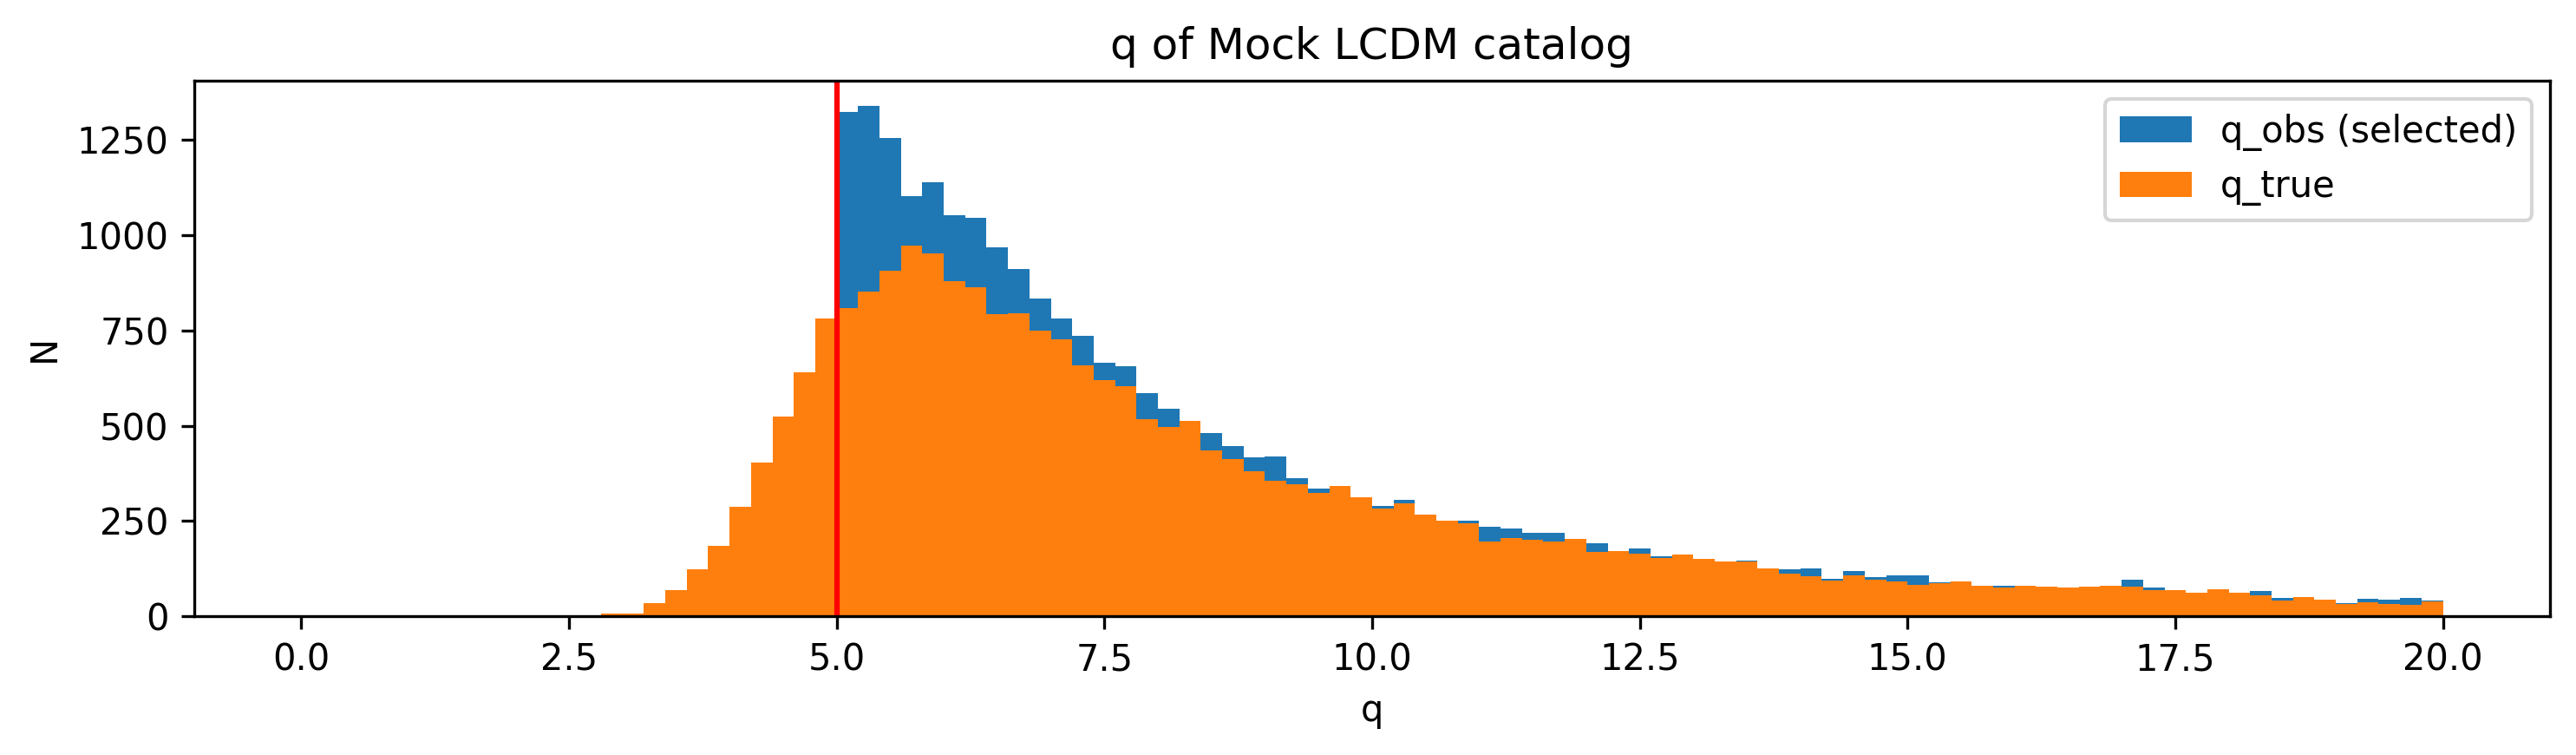

In [4]:
fig, axes = plt.subplots(1, 1, figsize=(10, 3), dpi=300)

axes.hist(cats['LCDM']['q_obs'], bins=100, range=(0, 20), label='q_obs (selected)')
axes.hist(cats['LCDM']['q_true'], bins=100, range=(0, 20), label='q_true')
#axes.hist(cats['LCDM']['q_mean'], bins=100, range=(0, 20), label='q_mean')
axes.axvline(cats['LCDM']['Q_TH'], color='r')

axes.set_title("q of Mock LCDM catalog")
axes.set_xlabel("q")
axes.set_ylabel("N")
axes.legend()

plt.tight_layout()
plt.show()

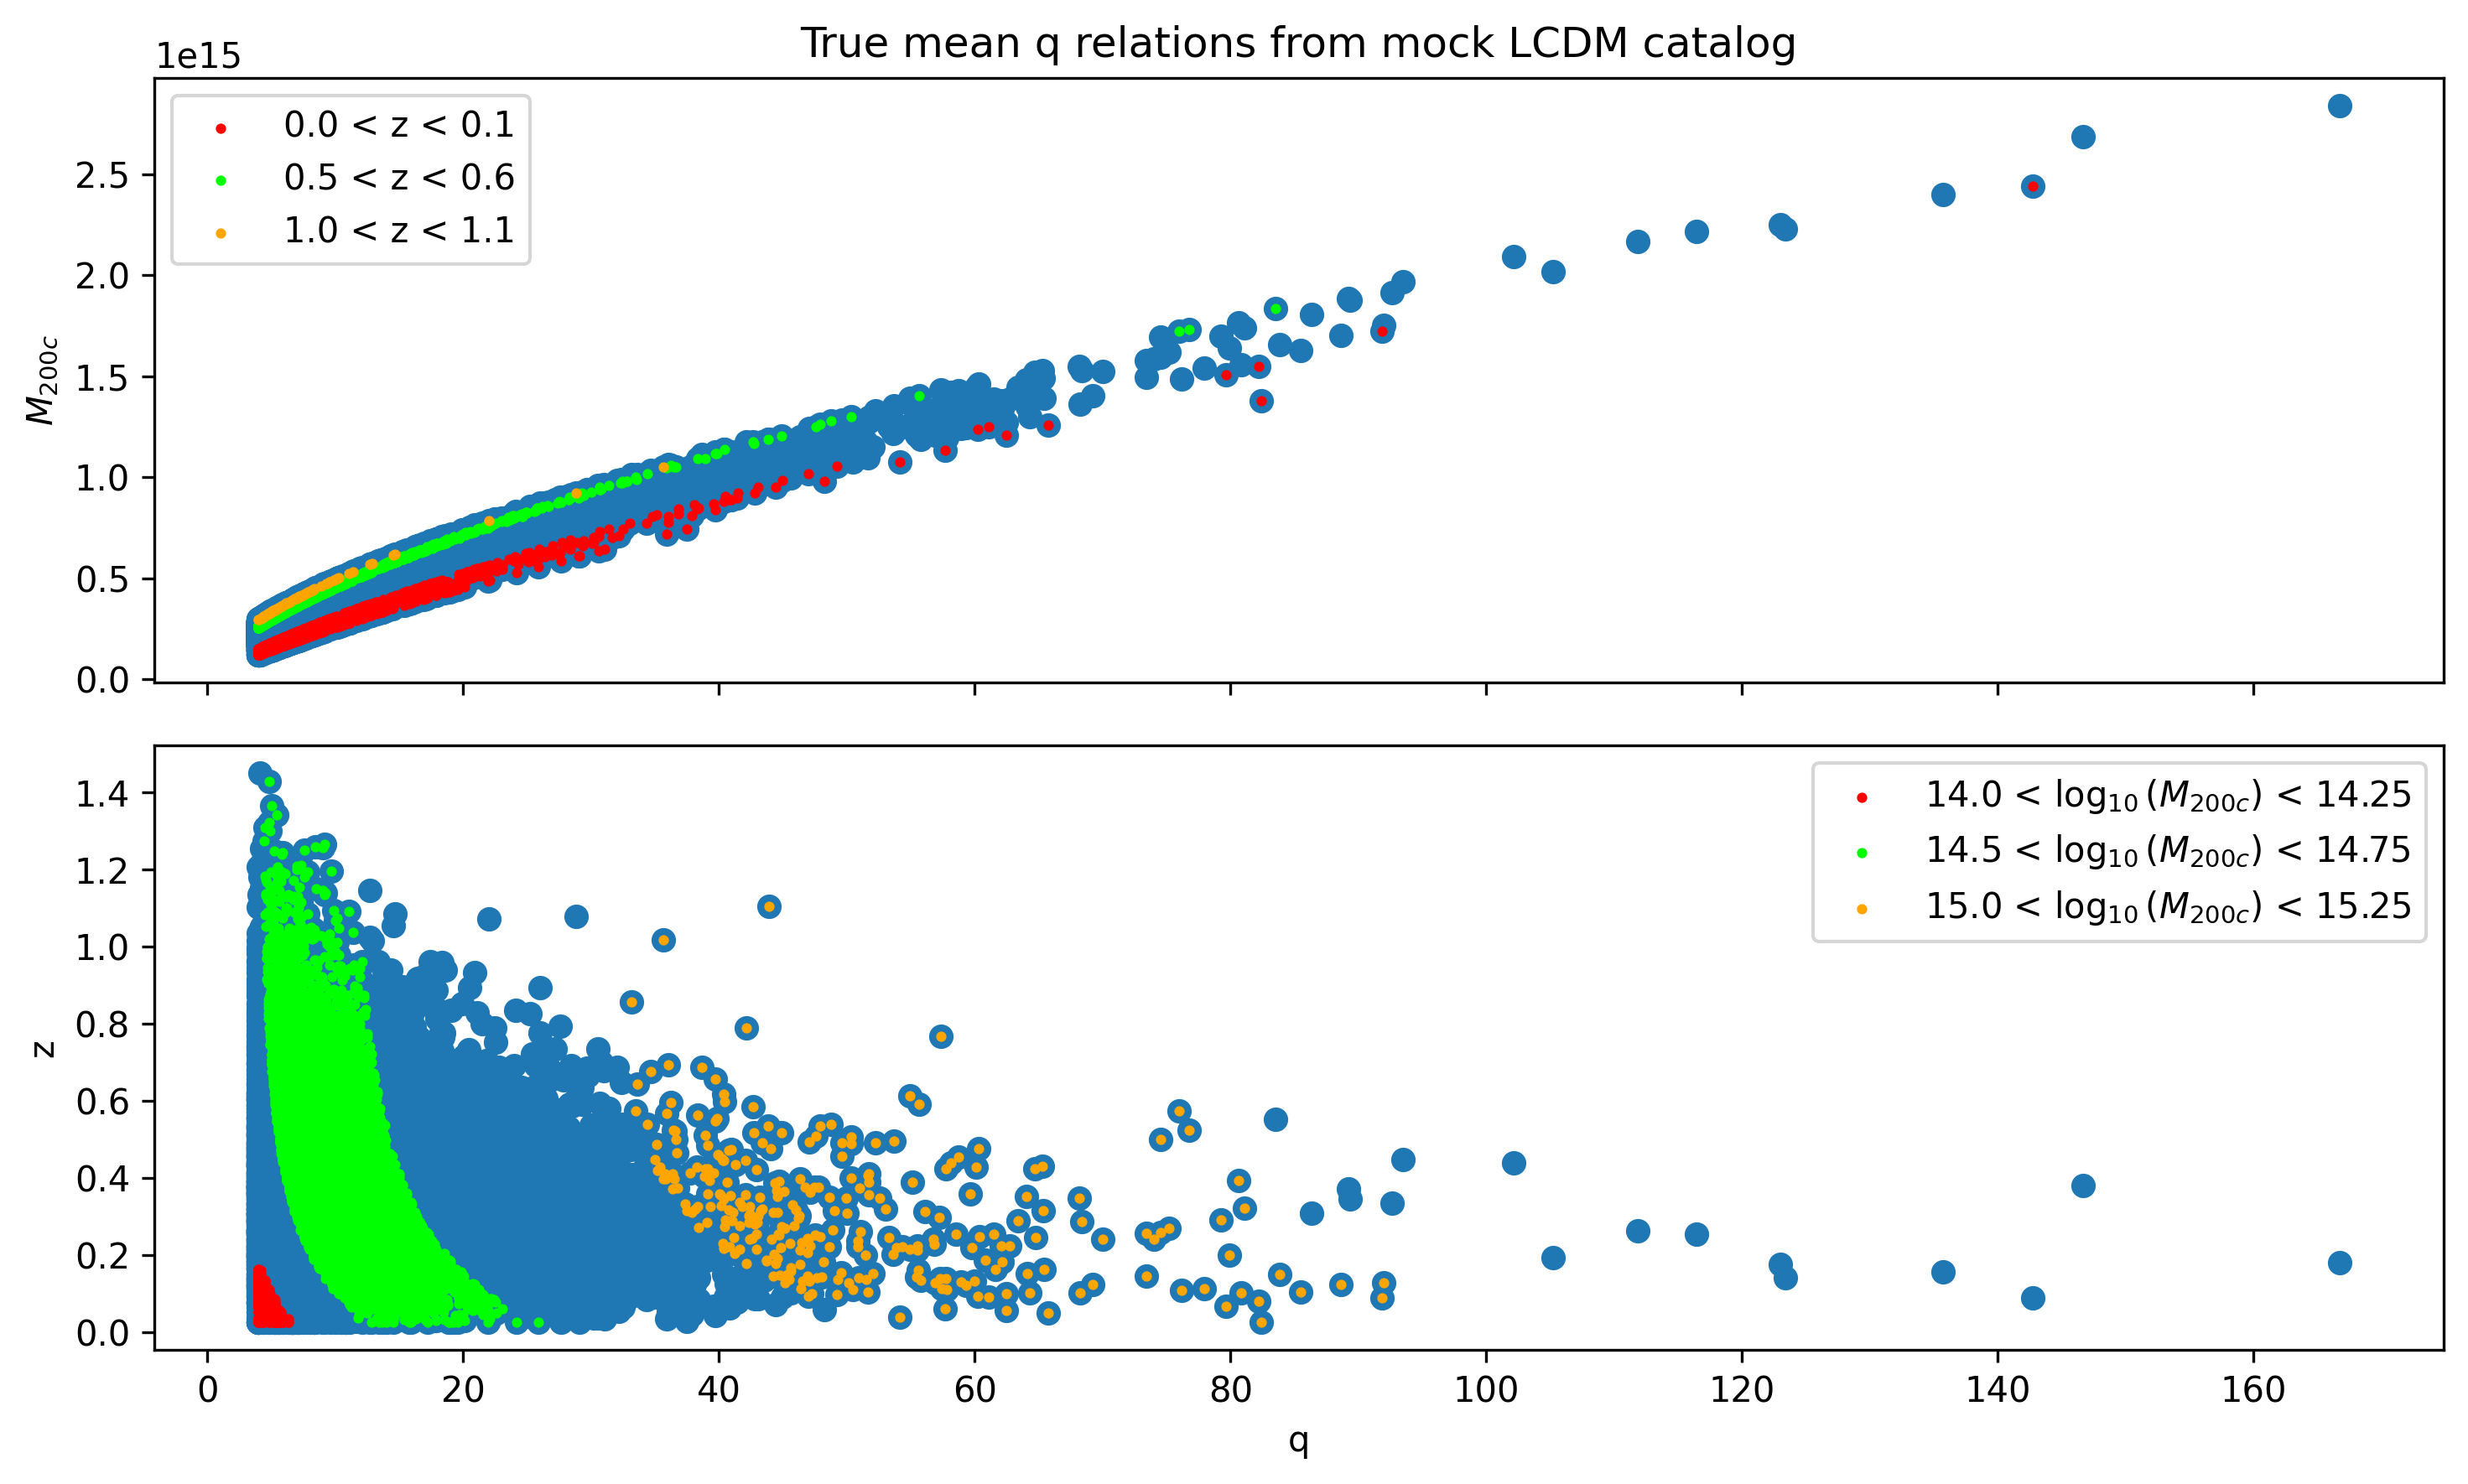

In [108]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), dpi=300, sharex=True)

ax0.scatter(catalogue['q_mean'],catalogue['M200c_true'])

zmin, zmax = 0.0, 0.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='red', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 0.5, 0.6
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='lime', s=15, label=f'{zmin} < z < {zmax}', marker='.')

zmin, zmax = 1.0, 1.1
mask = (catalogue['z'] > zmin) & (catalogue['z'] < zmax)
ax0.scatter(catalogue['q_mean'][mask],
            catalogue['M200c_true'][mask],
            c='orange', s=15, label=f'{zmin} < z < {zmax}', marker='.')
ax0.legend()
ax0.set_ylabel(r"$M_{{200c}}$")

ax1.scatter(catalogue['q_mean'],catalogue['z'])

Mmin, Mmax = 10**14, 10**14.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='red', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**14.5, 10**14.75
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='lime', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')
Mmin, Mmax = 10**15, 10**15.25
mask = (catalogue['M200c_true'] > Mmin) & (catalogue['M200c_true'] < Mmax)
ax1.scatter(catalogue['q_mean'][mask],
            catalogue['z'][mask],
            c='orange', s=15, label=fr'{np.round(np.log10(Mmin),2)} < $\log_{{10}}(M_{{200c}})$ < {np.round(np.log10(Mmax),2)}', marker='.')

ax1.legend()
ax1.set_ylabel("z")

ax1.set_xlabel("q")
ax0.set_title("True mean q relations from mock LCDM catalog")
plt.tight_layout()
plt.show()

##### Likelihood Code

###### Actual Likelihood Functionality

In [4]:
import pickle
import numpy as np
import os
import cosmocnc_axionHMcode_jax.cosmocnc_jax as cosmocnc
from wl_likelihoods import logP_gt_all, logP_gt_numerical
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    func_axionHMcode_D_z_unnorm_int,
    func_axionHMcode_D_z_unnorm)
from astropy.cosmology import FlatLambdaCDM
from scipy.integrate import simpson
import jax
import jax.numpy as jnp

h_fid       = 0.68
omega_b_fid = 0.0226576
ns_fid      = 0.965

omega_m_fid = 0.143344
#logAs_fid   = np.log(2.1e-09 * 1e10)
sigma_8_fid = 0.825264573 # found from axionHMcode

_SURVEY_SR  = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_sr_so_sim.py"
_SURVEY_CAT = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_cat_so_sim.py"

Z_ARR        = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/
defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/cosmocnc_axionHMcode_jax/cosmocnc_jax/


In [5]:
# Precompute a bunch of quantities so we dont have to do it on the fly, and can just interpolate
#################################################################################### COSMOLOGY CACHE
_astropy_cosmo_fid = FlatLambdaCDM(H0=h_fid*100., Om0=omega_m_fid/h_fid**2)
_omega_m_grid      = np.linspace(0.05, 0.30, 50)
_Om0_grid          = _omega_m_grid / h_fid**2
_z_table           = np.concatenate([np.linspace(1e-6, 1., 500), np.linspace(1., 100., 500)])
_z_source_bins     = np.array([0.285, 0.476, 0.743, 0.942])

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30

_cache_path = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_GRID_CACHE.pkl"
if os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table = pickle.load(f)
    print("Loaded precomputed tables from cache")
else:
    print("Precomputing tables (one-time cost)...")
    _G_a_grid  = np.array([
        func_axionHMcode_D_z_unnorm_int(
            0., Om0,
            lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
        for Om0 in _Om0_grid])
    _norm_grid = np.array([
    func_axionHMcode_D_z_unnorm(
        0., Om0,
        lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
    for Om0 in _Om0_grid])
    _D_table = np.zeros((len(_omega_m_grid), len(_z_table)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        E_z_i   = lambda z, c=cosmo_i: c.H(z).value / (h_fid * 100.)
        norm_i  = _norm_grid[i]
        _D_table[i] = [func_axionHMcode_D_z_unnorm(z, Om0, E_z_i) / norm_i
                       for z in _z_table]
    _DA_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        for j, z in enumerate(Z_ARR):
            _DA_table[i, j] = comoving_distance(
                {"cosmos": {"z": z, "h": h_fid,
                             "Omega_m_0": Om0, "Omega_w_0": 1.-Om0}}, z) / (1+z)
    _Sigma_crit_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        for j, z in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z]
            if len(usable) == 0:
                _Sigma_crit_table[i, j] = np.inf
                continue
            inv_scs = []
            DA_l = cosmo_i.angular_diameter_distance(z).value  # Mpc, astropy ← fix
            for z_s in usable:
                DA_s  = cosmo_i.angular_diameter_distance(z_s).value
                DA_ls = cosmo_i.angular_diameter_distance_z1z2(z, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * DA_l*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            _Sigma_crit_table[i, j] = 1./np.mean(inv_scs) if inv_scs else np.inf    
    with open(_cache_path, "wb") as f:
        pickle.dump((_G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table), f)
    print("Saved tables")


def _interp_omega_m(omega_m, table):
    """Linear interpolation over the omega_m grid."""
    w    = np.interp(omega_m/h_fid**2, _Om0_grid, np.arange(len(_Om0_grid), dtype=float))
    i_lo = int(np.clip(np.floor(w), 0, len(_Om0_grid)-2))
    frac = w - i_lo
    return (1.-frac)*table[i_lo] + frac*table[i_lo+1]

def get_G_a_interp(omega_m):        return np.interp(omega_m, _omega_m_grid, _G_a_grid)
def get_norm_interp(omega_m):       return np.interp(omega_m, _omega_m_grid, _norm_grid)
def get_D_grid_interp(omega_m):     return _z_table.copy(), _interp_omega_m(omega_m, _D_table)
def get_DA_grid_interp(omega_m):    return Z_ARR.copy(),    _interp_omega_m(omega_m, _DA_table)
def get_Sigma_crit_arr(omega_m):    return _interp_omega_m(omega_m, _Sigma_crit_table)

#################################################################################### PROFILE CACHE
import os
import pickle
import numpy as np
from tqdm import tqdm
from astropy.cosmology import FlatLambdaCDM
from scipy.interpolate import interp1d

from feedback_mimic import (
    get_NFW_profile, get_realspace_profile, get_some_quantities,
    dn_dlog10Mtot, Mtot_to_MDelta, get_tangential_shear
)

CACHE_PATH = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_SHEAR_LCDM_CACHE.npz"
if os.path.exists(CACHE_PATH):
    print("Shear cache already made")
else:
    HALO_INPUT_FILE = "/home/jange/scratch/FeedbackMimic/results/halo_model"
    
    # ── grids ─────────────────────────────────────────────────────────────────────
    h_fid         = 0.68
    omega_m_0_fid = 0.143344
    
    Z_ARR = np.linspace(0.0, 2.0, 81)
    Z_ARR = Z_ARR[Z_ARR > 0]
    
    K_ARR = np.logspace(-6, 6, 8192)
    R_ARR = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)
    
    M_TRANSITION     = 10**12.5
    M_DELTA          = 200
    M_REF_DENS       = "critical"
    R_PROJ_ARR_NUM   = 300
    R_FOR_SIGMA_NUM  = 100
    
    # ── KEY FIX: single common R grid for ALL redshifts ──────────────────────────
    # Use the smallest R_max across all z (= 3.2/(1+z_max)) so every z slice
    # covers the full grid. Profiles beyond a given z's r_vir will naturally
    # drop to zero; we never extrapolate outward.
    R_MAX_GLOBAL  = 3.2 / (1. + Z_ARR.min())   # ~1.6/(1+2) ≈ 0.533 Mpc/h for z_max=2
    R_proj_common = np.linspace(0.5, R_MAX_GLOBAL, R_PROJ_ARR_NUM)   # (nR,) fixed
    
    # ── Sigma_crit ────────────────────────────────────────────────────────────────
    _G_SI    = 6.674e-11
    _c_SI    = 2.998e8
    _Mpc_m   = 3.0857e22
    _Msol_kg = 1.989e30

    def compute_Sigma_crit_arr(omega_m, h_fid=h_fid,
                                _z_source_bins=np.array([0.285, 0.476, 0.743, 0.942])):
        Om0   = omega_m / h_fid**2
        cosmo = FlatLambdaCDM(H0=h_fid * 100.0, Om0=Om0)
        Sigma_crit_arr = np.zeros(len(Z_ARR))
        for j, z_l in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z_l]
            if len(usable) == 0:
                Sigma_crit_arr[j] = np.inf
                continue
            DA_l    = cosmo.angular_diameter_distance(z_l).value
            inv_scs = []
            for z_s in usable:
                DA_s  = cosmo.angular_diameter_distance(z_s).value
                DA_ls = cosmo.angular_diameter_distance_z1z2(z_l, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * DA_l*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            Sigma_crit_arr[j] = 1./np.mean(inv_scs) if inv_scs else np.inf
        return Sigma_crit_arr
    
    # Sigma_crit in Msol/h/(Mpc/h)^2
    Sigma_crit_arr = compute_Sigma_crit_arr(omega_m_0_fid) / h_fid
    
    # ── mass grid ─────────────────────────────────────────────────────────────────
    lnM_min    = np.log(10**13.5)
    lnM_max    = np.log(1e16)
    N_M        = 600
    lnM_common = np.linspace(lnM_min, lnM_max, N_M)   # log(M200c [Msol/h])
    M_common   = np.exp(lnM_common)
    
    # ── allocate output arrays ────────────────────────────────────────────────────
    nZ = len(Z_ARR)
    nM = N_M
    nR = R_PROJ_ARR_NUM
    
    GT_cache = np.zeros((nZ, nM, nR))
    DS_cache = np.zeros((nZ, nM, nR))
    S_cache  = np.zeros((nZ, nM, nR))
    
    # ── main loop ─────────────────────────────────────────────────────────────────
    print("Computing shear cache...")
    for iz, z in enumerate(tqdm(Z_ARR)):
    
        with open(f"{HALO_INPUT_FILE}/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
            data = pickle.load(f)
    
        Mtot, _ = dn_dlog10Mtot(data, 'LCDM')
        r_t, _, _, _, r_s, _, _, _ = get_some_quantities(data, axion_dic=None)
    
        valid  = Mtot > M_TRANSITION
        Mtot_v = Mtot[valid]
        r_t_v  = r_t[valid]
        r_s_v  = r_s[valid]
    
        rho_v = get_realspace_profile(
            u_k=get_NFW_profile(r_v=r_t_v, k_arr=K_ARR, r_s=r_s_v, r_t=r_t_v),
            r_arr=R_ARR, k_arr=K_ARR, M_arr=Mtot_v, r_t=r_t_v)
    
        M200c, _ = Mtot_to_MDelta(
            data, r_t=r_t_v, M_arr=Mtot_v, r_arr=R_ARR,
            Del=M_DELTA, reference_density=M_REF_DENS,
            axion_dic=None, rho=rho_v, k_arr=K_ARR)
    
        # ── KEY FIX: pass R_proj_common so every z uses the same R grid ──────────
        GT_raw, DS_raw, S_raw, R_proj_out = get_tangential_shear(
            rho_v, R_ARR, z, Mtot_v, M200c, r_t_v,
            Sigma_crit_arr[iz],
            R_min=R_proj_common[0],
            R_max=R_proj_common[-1],          # same R_max for every z
            R_proj_arr_num=R_PROJ_ARR_NUM,
            R_for_Sigma_num=R_FOR_SIGMA_NUM,
            M_min_to_consider=M_TRANSITION,
            full_output=True)
    
        # verify R_proj_out matches (it should by construction)
        assert np.allclose(R_proj_out, R_proj_common, rtol=1e-6), \
            f"R grid mismatch at z={z}"
    
        # filter valid entries and sort by M200c
        valid2    = M200c > 0
        lnM_nat   = np.log(M200c[valid2])
        GT_valid  = np.array([GT_raw[i] for i in range(len(M200c))
                              if valid2[i] and GT_raw[i] is not None])
        DS_valid  = np.array([DS_raw[i] for i in range(len(M200c))
                              if valid2[i] and DS_raw[i] is not None])
    
        # Sigma is on R_for_Sigma (log grid); resample onto R_proj_common
        R_for_Sigma = np.logspace(np.log10(1e-4), np.log10(R_proj_common[-1]),
                                  R_FOR_SIGMA_NUM)
        S_valid = np.array([
            np.interp(R_proj_common, R_for_Sigma, np.array(S_raw[i]))
            for i in range(len(M200c))
            if valid2[i] and S_raw[i] is not None])
    
        lnM_valid = lnM_nat[[GT_raw[i] is not None
                              for i in range(len(lnM_nat))]]
    
        order     = np.argsort(lnM_valid)
        lnM_valid = lnM_valid[order]
        GT_valid  = GT_valid[order]
        DS_valid  = DS_valid[order]
        S_valid   = S_valid[order]
    
        # interpolate onto common lnM grid for each R bin
        for ir in range(nR):
            GT_cache[iz, :, ir] = np.interp(lnM_common, lnM_valid, GT_valid[:, ir],
                                             left=0., right=0.)
            DS_cache[iz, :, ir] = np.interp(lnM_common, lnM_valid, DS_valid[:, ir],
                                             left=0., right=0.)
            S_cache[iz,  :, ir] = np.interp(lnM_common, lnM_valid, S_valid[:, ir],
                                             left=0., right=0.)
    
    np.savez(CACHE_PATH,
             GT_cache   = GT_cache,       # (nZ, nM, nR)
             DS_cache   = DS_cache,       # (nZ, nM, nR)
             S_cache    = S_cache,        # (nZ, nM, nR)
             R_proj     = R_proj_common,  # (nR,)  SINGLE common grid — key fix
             Z_ARR      = Z_ARR,          # (nZ,)
             lnM_common = lnM_common)     # (nM,)  log(M200c Msol/h)
    
    print(f"Saved to {CACHE_PATH}")
    print(f"Grid: nZ={nZ}, nM={nM}, nR={nR}")
    print(f"R grid: {R_proj_common[0]:.3f} to {R_proj_common[-1]:.3f} Mpc/h (FIXED for all z)")
    print(f"lnM:    {lnM_min:.2f} to {lnM_max:.2f}  "
          f"({np.exp(lnM_min):.2e} to {np.exp(lnM_max):.2e} Msol/h)")

Loaded precomputed tables from cache
Shear cache already made


In [7]:
# one nc object per catalogue, initialised lazily
_nc_cache = {}

def _get_nc(catalogue_name):
    if catalogue_name not in _nc_cache:
        nc = cosmocnc.cluster_number_counts()
        nc.cnc_params.update({
            "survey_sr"                : _SURVEY_SR,
            "survey_cat"               : _SURVEY_CAT,
            "obs_select"               : "q_so_sim",
            "observables"              : [["q_so_sim"]],
            "obs_select_min"           : 5.,
            "obs_select_max"           : 300.0,
            "z_min"                    : Z_ARR[0],
            "z_max"                    : Z_ARR[-1],
            "M_min"                    : 10**13.5 / h_fid,
            "M_max"                    : 1e16 / h_fid,
            "cluster_catalogue"        : catalogue_name,
            "likelihood_type"          : "unbinned",
            "data_lik_from_abundance"  : False,
            "scalrel_type_deriv"       : "analytical",
            "n_points"                 : 1000,
            "n_z"                      : len(Z_ARR),
            "cosmology_tool"           : "classy_sz_jax",
            "power_spectrum_type"      : "cosmopower",
            "cosmo_amplitude_parameter": "sigma_8",
            "hmf_calc"                 : "cnc",
            "hmf_type"                 : "ST_axionHMcode",
            "mass_definition"          : "200c",
            "number_cores_hmf"         : 1,
            "number_cores_abundance"   : 1,
            "number_cores_data"        : 1,
            "cosmocnc_verbose"         : "none",
            "return_profile_params"    : True,
            "stacked_likelihood"       : False,
            "non_validated_clusters"   : False,
        })
        nc.initialise()
        _nc_cache[catalogue_name] = nc
    return _nc_cache[catalogue_name]


def get_log_likelihood(
    catalogue_name,
    # ── free parameters ──
    omega_m  = omega_m_fid,
    sigma_8    = sigma_8_fid,
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz  = 2.0,
    b_WL_0    = 0.0, 
    b_WL_M    = 1.0,
    # ── fixed ────────────
    bias_sz       = 0.8,
    sigma_lnq     = 0.0,#0.173, -> for now this is using q_mean as the variable
    dof           = 0.0,
    q_cutoff      = 5.0,
    M_WL_pivot    = 2e14, # Msol/h
    wl_catalogue = None,
    sigma_shape = 0.37,
    n_source    = 5.5,  # arcmin^-2
    return_nc = False,
    use_shear_cache = False, # True to use the numerical, interpolated, truncated NFW profiles rather than just the analytic ones
    wl_z_max = None, # cuts off the max z that we use to constrain wl bias params
    wl_only = False,        # no abundance or SZ data -> use broad flat mass prior
    wl_n_mass_points = 200, # esolution of the broad mass grid if wl_only
):
    """
    Returns  ln L = -N_bar + sum_i ln P(q_obs,i, z_i | params).
    First call per catalogue_name runs initialise() (slow).
    Subsequent calls only run reinitialise() (fast).
    """
    nc = _get_nc(catalogue_name)
    z_table, D_grid = get_D_grid_interp(omega_m)

    nc.cosmo_params.update({
        "Om0"     : omega_m / h_fid**2,
        "Ob0"     : omega_b_fid / h_fid**2,
        "h"       : h_fid,
        "sigma_8" : sigma_8,
        "n_s"     : ns_fid,
        "m_nu"    : 0.06,
        "tau_reio": 0.0544,
        "n_mass_points_coarse": 50,
        # ── These are necessary to make ST_axionHMcode fast ──
        "G_a_precomputed":           get_G_a_interp(omega_m),
        "D_grid_z_precomputed":      z_table,
        "D_grid_precomputed":        D_grid,
        "normalisation_precomputed": get_norm_interp(omega_m),
        "Sigma_crit_vec": get_Sigma_crit_arr(omega_m)
    })
    nc.scal_rel_params.update({
        "A_szifi"        : A_sz,
        "alpha_szifi"    : alpha_sz,
        "beta_szifi"     : beta_sz,
        "bias_sz"        : bias_sz,
        "sigma_lnq_szifi": sigma_lnq,
        "dof"            : dof,
        "q_cutoff"       : q_cutoff,
    })

    try:
        nc.reinitialise()
        nc.get_hmf(return_profile_params=True)
        log_lik_sz_cosmocnc = nc.get_log_lik()
    except Exception as e:
        print(f"cosmocnc_jax failed: {e}")
        return -np.inf
    P_q_and_hmf_kernel = nc.bc_cpdf_array

    if wl_catalogue is not None:
        z_wl    = np.asarray(nc.bc_z_clusters)
        lnM_arr = np.asarray(nc.bc_lnM_array)     # (n_cl, n_pts), ln(M/1e14 Msol)
        cwh     = np.asarray(nc.bc_cpdf_array)     # (n_cl, n_pts), unnormalised
        n_cl = len(z_wl)
    
        # NFW profile on the full mass grid (n_cl, n_pts)
        profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)
        rho_crit_per_cluster = np.interp(z_wl, Z_ARR, np.asarray(nc.rho_c))  # Msol/Mpc^3
        R_200c_per_cluster   = (3. * np.exp(lnM_arr) * 1e14             # M in Msol on grid
                                / (4. * np.pi * rho_crit_per_cluster[:, None] * 200.))**(1./3.)
        # r_s in Mpc (from profile), c_200c dimensionless
        c_200c = R_200c_per_cluster / profile['r_s']   # (n_cl, n_pts)
        rho_m_h      = profile['rho_m']      * h_fid**3   # Msol/(h^-1 Mpc)^3
        rho_crit_z_h = rho_crit_per_cluster  / h_fid**2
        r_s_h        = profile['r_s']        * h_fid       # h^-1 Mpc
        r_vir_h = profile['R_vir'] * h_fid
    
        # Sigma_crit: Msol/Mpc^2 → Msol/(h^-1 Mpc)^2
        #Sigma_crit_wl = np.interp(z_wl, Z_ARR,
        #        get_Sigma_crit_arr(omega_m)) * h_fid   # (n_cl,)
        iz_wl = np.argmin(np.abs(Z_ARR[:, None] - z_wl[None, :]), axis=0)
        Sigma_crit_wl = get_Sigma_crit_arr(omega_m)[iz_wl] / h_fid
        # treating it like a step function rather than something continuous
    
        # DA for annulus area: Mpc → h^-1 Mpc
        DA_z_arr, DA_arr = get_DA_grid_interp(omega_m)
        DA_halo = np.interp(wl_catalogue['z'], DA_z_arr, DA_arr) * h_fid
    
        # ── Radial grid (h^-1 Mpc), same convention as Bocquet ──
        z_wl_cat = wl_catalogue['z']
        gt_orig  = np.asarray(wl_catalogue["gt_true"])
        R_orig   = np.asarray(wl_catalogue["R_proj_arr"])
        DR = 0.1  # h^-1 Mpc

        R_new_list, gt_new_list = [], []
        for i, zi in enumerate(z_wl_cat):
            r_min  = 0.5
            r_max  = 3.2 / (1. + zi)
            n_bins = max(int(np.round((r_max - r_min) / DR)) + 1, 2)
            r_new  = np.linspace(r_min, r_max, n_bins)
            R_new_list.append(r_new)
            gt_new_list.append(np.interp(r_new, R_orig[i], gt_orig[i]))
    
        N_R    = max(len(r) for r in R_new_list)
        R_proj = np.array([np.pad(r,  (0, N_R - len(r)),  constant_values=r[-1])
                           for r in R_new_list])
        gt_obs = np.array([np.pad(gt, (0, N_R - len(gt)), constant_values=0.)
                           for gt in gt_new_list])
    
        dR_arr = np.gradient(R_proj, axis=1)
        A_ann  = (2.*np.pi * R_proj * dR_arr
                  * (180.*60./np.pi / DA_halo[:, None])**2)
        sigma_g = sigma_shape / np.sqrt(np.maximum(n_source * A_ann, 1.))
        
        # Mask padded bins
        for i, r_new in enumerate(R_new_list):
            sigma_g[i, len(r_new):] = 1e10
        
        for i, r_new in enumerate(R_new_list):
            dR_i = np.gradient(r_new)                          # gradient on real bins only
            A_ann_i = (2.*np.pi * r_new * dR_i
                       * (180.*60./np.pi / DA_halo[i])**2)
            sigma_g[i, :len(r_new)] = sigma_shape / np.sqrt(
                np.maximum(n_source * A_ann_i, 1.))
            sigma_g[i, len(r_new):] = 1e10
        if wl_z_max is not None:
            above_zmax = z_wl_cat > wl_z_max   # (n_cl,) boolean
            sigma_g[above_zmax, :] = 1e10
            
        if wl_only:
            # Broad flat prior: same grid for every cluster
            lnM_lo  = np.log(10**13.5)
            lnM_hi  = np.log(1e16)
            lnM_int = np.linspace(lnM_lo, lnM_hi, wl_n_mass_points)  # log(Msol/h)
            M_arr_wl = jnp.array(                                      # (n_cl, n_pts_wl) Msol/h
                np.tile(np.exp(lnM_int), (n_cl, 1)))
            lnM_sz_in_Msol_h = lnM_arr + np.log(1e14) + np.log(h_fid)
            c_200c_wl = np.array([
                np.interp(lnM_int, lnM_sz_in_Msol_h[i], c_200c[i],
                          left=c_200c[i, 0], right=c_200c[i, -1])
                for i in range(n_cl)])   # (n_cl, n_pts_wl)
        
            lnM_for_simpson = lnM_int   # 1D, common for all clusters
        else:
            # Use SZ posterior grid as before
            M_arr_wl      = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
            c_200c_wl     = c_200c                              # (n_cl, n_pts)
            lnM_for_simpson = nc.bc_lnM_array      

        # ── Compute logP_gt ────────────────────────────────────────────────
        if use_shear_cache:
            logP_gt = logP_gt_numerical(
                gt_obs, sigma_g, R_proj,
                M_arr_wl, rho_crit_z_h, c_200c_wl,
                Sigma_crit_wl, b_WL_0, b_WL_M, M_WL_pivot, z_wl)
        else:
            logP_gt = logP_gt_all(
                jnp.array(gt_obs), jnp.array(sigma_g), jnp.array(R_proj),
                M_arr_wl, rho_crit_z_h, c_200c_wl,
                jnp.array(Sigma_crit_wl), jnp.array(b_WL_0), jnp.array(b_WL_M), M_WL_pivot)   # (n_cl, n_pts_wl)

        # ── Integrate over mass ────────────────────────────────────────────
        if wl_only:
            # Flat prior: all clusters use the same lnM axis
            P_kernel = jnp.exp(logP_gt)
        else:
            # SZ posterior: per-cluster lnM axis (as before)
            P_kernel = jnp.exp(logP_gt) * P_q_and_hmf_kernel
            
        cluster_liks = simpson(P_kernel, x=lnM_for_simpson, axis=1)
        cluster_liks = jnp.maximum(cluster_liks, 1e-300)

        if wl_only:
            log_lik = float(jnp.sum(jnp.log(cluster_liks)))
        else:
            log_lik = float(-nc.n_tot + jnp.sum(jnp.log(cluster_liks)))
    else:
        P_kernel = P_q_and_hmf_kernel

        cluster_liks = simpson(
            P_kernel,
            x=nc.bc_lnM_array,
            axis=1
        )
        cluster_liks = jnp.maximum(cluster_liks, 1e-300)
        log_lik = (-nc.n_tot + np.sum(np.log(cluster_liks)))
        log_lik = (np.sum(np.log(cluster_liks)))
    if return_nc:
        return float(log_lik), nc
    return float(log_lik)

###### Consistency Checks

In [49]:
import numpy as np
from astropy.cosmology import FlatLambdaCDM
from astropy import units as u

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30


# ── NFW helper functions (pure numpy) ────────────────────────────────────────

def _f_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.ones_like(x)
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.arctanh(np.sqrt(1. - x[lt]**2)) / np.sqrt(1. - x[lt]**2)
    out[gt] = np.arctan( np.sqrt(x[gt]**2 - 1.)) / np.sqrt(x[gt]**2 - 1.)
    return out

def _g_nfw_np(x):
    x   = np.asarray(x, dtype=float)
    out = np.full_like(x, 1. + np.log(0.5))
    lt  = x < 1.
    gt  = x > 1.
    out[lt] = np.log(x[lt]/2.) + np.arctanh(np.sqrt(1.-x[lt]**2)) / np.sqrt(1.-x[lt]**2)
    out[gt] = np.log(x[gt]/2.) + np.arctan( np.sqrt(x[gt]**2-1.)) / np.sqrt(x[gt]**2-1.)
    return out

def gt_nfw_analytic(R_bins_Mpc_h, M_Msol_h, rho_crit_h, c_200c, Sigma_crit_h):
    """
    Analytic NFW reduced tangential shear.

    All inputs in h-unit system:
        R_bins_Mpc_h   : (nR,)  projected radii        [Mpc/h]
        M_Msol_h       : scalar M_200c                 [Msol/h]
        rho_crit_h     : scalar rho_crit(z)            [Msol/h / (Mpc/h)^3]
                         = rho_crit_astropy / h^2
        c_200c         : scalar concentration          [dimensionless]
        Sigma_crit_h   : scalar critical surface dens  [Msol/h / (Mpc/h)^2]
                         = Sigma_crit_table * h

    Returns gt : (nR,) dimensionless reduced shear
    """
    r_200 = (3. * M_Msol_h / (4. * np.pi * 200. * rho_crit_h))**(1./3.)  # Mpc/h
    r_s   = r_200 / c_200c                                                  # Mpc/h
    g_c   = np.log(1. + c_200c) - c_200c / (1. + c_200c)
    rho_s = M_Msol_h / (4. * np.pi * r_s**3 * g_c)                        # Msol/h/(Mpc/h)^3

    x         = R_bins_Mpc_h / r_s
    Sigma     = 2. * rho_s * r_s / (x**2 - 1.) * (1. - _f_nfw_np(x))     # Msol/h/(Mpc/h)^2
    Sigma_bar = 4. * rho_s * r_s / x**2 * _g_nfw_np(x)                    # Msol/h/(Mpc/h)^2
    return (Sigma_bar - Sigma) / (Sigma_crit_h - Sigma)


# ── Main check function ───────────────────────────────────────────────────────

def run_checks(nc, catalogue, omega_m, h_fid=0.68,
               cluster_indices=None, Z_ARR=None,
               get_Sigma_crit_arr=None):
    """
    Parameters
    ----------
    nc                  : cosmocnc object after get_log_lik()
    catalogue           : mock catalogue dict
    omega_m             : physical matter density (Omega_m * h^2)
    h_fid               : Hubble parameter
    cluster_indices     : list of catalogue indices to check
    Z_ARR               : redshift array used in cosmocnc
    get_Sigma_crit_arr  : function(omega_m) → (n_z,) Msol/Mpc^2
    """
    if cluster_indices is None:
        cluster_indices = [0, 50, 200]
    if Z_ARR is None:
        Z_ARR = np.linspace(0., 2., 81)[1:]

    z_wl    = np.asarray(nc.bc_z_clusters)
    lnM_arr = np.asarray(nc.bc_lnM_array)
    rho_c_vec = np.asarray(nc.rho_c)          # Msol/Mpc^3, on Z_ARR grid
    profile = nc.get_profile_params_at_clusters(z_wl, lnM_arr)

    SEP = "=" * 70

    # ── Section 1: Unit conversion verification ───────────────────────────────
    print(SEP)
    print("SECTION 1: UNIT CONVERSION VERIFICATION")
    print(SEP)
    print("Confirmed conversions (from physical R200c check):")
    print("  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3")
    print("  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2")
    print()

    # Verify rho_crit conversion using R200c at a reference cluster
    ci_ref = cluster_indices[0]
    bc_pos = np.where(nc.bc_cluster_indices == ci_ref)[0]
    if len(bc_pos) == 0:
        print(f"  Warning: cluster {ci_ref} not in bc_cluster_indices, skipping rho_crit check")
    else:
        pos   = bc_pos[0]
        z_ref = float(catalogue['z'][ci_ref])
        M_ref_h   = float(catalogue['M200c_true'][ci_ref])    # Msol/h
        M_ref_Msol = M_ref_h / h_fid                           # Msol
        iz    = int(np.argmin(np.abs(Z_ARR - z_ref)))
        rho_crit_raw = float(np.interp(z_ref, Z_ARR, rho_c_vec))  # Msol/Mpc^3

        # Physical R200c (no h)
        R200c_Mpc   = (M_ref_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h = R200c_Mpc * h_fid

        # Mock R200c
        R200c_mock = float(np.interp(np.log(M_ref_h),
                                      np.log(catalogue['M200c_slices'][iz]),
                                      catalogue['R200c_slices'][iz]))

        # rho_crit / h^2 version
        rho_crit_h = rho_crit_raw / h_fid**2
        R200c_check = (M_ref_h / ((4*np.pi/3)*200*rho_crit_h))**(1./3.)

        print(f"  Reference cluster ci={ci_ref}, z={z_ref:.3f}, M={M_ref_h:.3e} Msol/h")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit / h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  R200c physical (Mpc→Mpc/h):       {R200c_Mpc:.4f} → {R200c_Mpc_h:.4f}")
        print(f"  R200c from rho_crit/h^2:           {R200c_check:.4f} Mpc/h")
        print(f"  R200c from mock catalogue:          {R200c_mock:.4f} Mpc/h")
        print(f"  Ratio (check/physical):             {R200c_check/R200c_Mpc_h:.6f}  ← expect 1.000")
        print()

    # Verify Sigma_crit conversion
    if get_Sigma_crit_arr is not None:
        z_test = 0.3
        #Sigma_raw = float(np.interp(z_test, Z_ARR, get_Sigma_crit_arr(omega_m)))
        iz_wl = np.argmin(np.abs(Z_ARR - z_test), axis=0)
        Sigma_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        Sigma_h   = Sigma_raw / h_fid**2

        # External check: astropy
        Om0   = omega_m / h_fid**2
        cosmo = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        # Use z_source = 0.742 (third source bin)
        z_s   = 0.743
        DA_l  = cosmo.angular_diameter_distance(z_test).value
        DA_s  = cosmo.angular_diameter_distance(z_s).value
        DA_ls = cosmo.angular_diameter_distance_z1z2(z_test, z_s).value
        Sigma_crit_ext = (_c_SI**2 / (4*np.pi*_G_SI)
                          * DA_s / (DA_l * DA_ls) / _Mpc_m
                          * _Mpc_m**2 / _Msol_kg)   # Msol/Mpc^2

        print(f"  Sigma_crit at z={z_test} (single source z_s={z_s}):")
        print(f"  From table (Msol/Mpc^2):           {Sigma_raw:.4e}")
        print(f"  Astropy external (Msol/Mpc^2):     {Sigma_crit_ext:.4e}")
        print(f"  Ratio table/astropy:                {Sigma_raw/Sigma_crit_ext:.4f}  ← expect ~1 (multi-source average)")
        print(f"  Table * h (Msol/h/(Mpc/h)^2):      {Sigma_h:.4e}")
        print()

    # ── Section 2: Per-cluster checks ─────────────────────────────────────────
    print(SEP)
    print("SECTION 2: PER-CLUSTER SHEAR COMPARISON")
    print(SEP)

    ratios_all = []

    for ci in cluster_indices:
        bc_pos = np.where(nc.bc_cluster_indices == ci)[0]
        if len(bc_pos) == 0:
            print(f"  Cluster ci={ci} not found in bc_cluster_indices, skipping.")
            continue
        pos = bc_pos[0]

        z_cl      = float(catalogue['z'][ci])
        M_true_h  = float(catalogue['M200c_true'][ci])   # Msol/h
        M_true_Msol = M_true_h / h_fid                    # Msol
        iz        = int(np.argmin(np.abs(Z_ARR - z_cl)))

        # rho_crit
        rho_crit_raw = float(np.interp(z_cl, Z_ARR, rho_c_vec))  # Msol/Mpc^3
        rho_crit_h   = rho_crit_raw / h_fid**2                    # Msol/h/(Mpc/h)^3

        # R200c
        R200c_Mpc    = (M_true_Msol / ((4*np.pi/3)*200*rho_crit_raw))**(1./3.)
        R200c_Mpc_h  = R200c_Mpc * h_fid
        R200c_mock   = float(np.interp(np.log(M_true_h),
                                        np.log(catalogue['M200c_slices'][iz]),
                                        catalogue['R200c_slices'][iz]))

        # r_s from cosmocnc profile at true mass
        M_coarse_Msol = np.asarray(nc.profile_params['M_vec'])      # Msol
        r_s_coarse    = nc.profile_params['r_s'][iz]                 # Mpc
        r_s_Mpc       = float(np.interp(np.log(M_true_Msol/1e14),
                                         np.log(M_coarse_Msol/1e14),
                                         r_s_coarse))
        r_s_Mpc_h     = r_s_Mpc * h_fid                              # Mpc/h
        c_200c        = R200c_Mpc / r_s_Mpc                          # dimensionless

        # Sigma_crit
        if get_Sigma_crit_arr is not None:
            iz_wl = np.argmin(np.abs(Z_ARR - z_cl), axis=0)
            Sigma_crit_raw = get_Sigma_crit_arr(omega_m)[iz_wl]
        else:
            Sigma_crit_raw = float(catalogue['Sigma_crit'][iz]) * h_fids
        Sigma_crit_h = Sigma_crit_raw / h_fid   # Msol/h/(Mpc/h)^2

        # Mock Sigma_crit
        Sigma_crit_mock_raw = float(catalogue['Sigma_crit'][iz]) * h_fid  # Msol/Mpc^2
        Sigma_crit_mock_h   = Sigma_crit_mock_raw / h_fid

        # Radial bins and observed shear
        R_proj_mock = np.asarray(catalogue['R_proj_arr'][ci])   # Mpc/h
        gt_mock     = np.asarray(catalogue['gt_true'][ci])      # dimensionless

        # Analytic NFW at true mass
        gt_analytic = gt_nfw_analytic(R_proj_mock, M_true_h, rho_crit_h,
                                       c_200c, Sigma_crit_h)

        # NFW intermediate quantities for inspection
        r_200_h  = R200c_Mpc_h
        g_c      = np.log(1.+c_200c) - c_200c/(1.+c_200c)
        rho_s_h  = M_true_h / (4.*np.pi * r_s_Mpc_h**3 * g_c)
        x0       = R_proj_mock[0] / r_s_Mpc_h
        Sigma0   = 2.*rho_s_h*r_s_Mpc_h/(x0**2-1.)*(1.-_f_nfw_np(np.array([x0]))[0])
        SigBar0  = 4.*rho_s_h*r_s_Mpc_h/x0**2*_g_nfw_np(np.array([x0]))[0]
        DS0      = SigBar0 - Sigma0

        n_show   = min(5, len(gt_mock))
        valid    = np.abs(gt_analytic) > 1e-10
        ratio_arr = np.where(valid, gt_mock / gt_analytic, np.nan)
        mean_ratio = float(np.nanmean(ratio_arr))
        ratios_all.append((ci, z_cl, M_true_h, c_200c, mean_ratio))

        print(f"\n{'─'*70}")
        print(f"ci={ci}  z={z_cl:.4f}  M200c={M_true_h:.3e} Msol/h")
        print(f"{'─'*70}")

        print(f"\n  ── Geometry ──")
        print(f"  R200c physical (Mpc/h):    {R200c_Mpc_h:.4f}")
        print(f"  R200c from mock catalogue: {R200c_mock:.4f}")
        print(f"  Ratio:                     {R200c_Mpc_h/R200c_mock:.5f}  ← expect 1.000")
        print(f"  r_s (Mpc/h):               {r_s_Mpc_h:.4f}")
        print(f"  c_200c = R200c/r_s:        {c_200c:.4f}")

        print(f"\n  ── Densities ──")
        print(f"  rho_crit (Msol/Mpc^3):           {rho_crit_raw:.4e}")
        print(f"  rho_crit/h^2 (Msol/h/(Mpc/h)^3): {rho_crit_h:.4e}")
        print(f"  rho_s (Msol/h/(Mpc/h)^3):        {rho_s_h:.4e}")
        print(f"  rho_s / rho_crit_h:               {rho_s_h/rho_crit_h:.1f}")

        print(f"\n  ── Sigma_crit ──")
        print(f"  From likelihood table (Msol/Mpc^2):  {Sigma_crit_raw:.4e}")
        print(f"  From mock catalogue   (Msol/Mpc^2):  {Sigma_crit_mock_raw:.4e}")
        print(f"  Ratio likelihood/mock:                {Sigma_crit_raw/Sigma_crit_mock_raw:.5f}  ← expect ~1.000")
        print(f"  Sigma_crit_h = /h (Msol/h/(Mpc/h)^2): {Sigma_crit_h:.4e}")
        print(f"  Mock Sigma_crit_h      (Msol/h/(Mpc/h)^2): {Sigma_crit_mock_h:.4e}")

        print(f"\n  ── DeltaSigma at R[0]={R_proj_mock[0]:.3f} Mpc/h ──")
        print(f"  Sigma     (Msol/h/(Mpc/h)^2): {Sigma0:.4e}")
        print(f"  SigmaBar  (Msol/h/(Mpc/h)^2): {SigBar0:.4e}")
        print(f"  DeltaSigma(Msol/h/(Mpc/h)^2): {DS0:.4e}")
        print(f"  kappa = Sigma/Sigma_crit:      {Sigma0/Sigma_crit_h:.5f}")
        print(f"  gt_analytic[0]:                {gt_analytic[0]:.6f}")
        print(f"  gt_mock[0]:                    {gt_mock[0]:.6f}")
        print(f"  ratio mock/analytic [0]:       {gt_mock[0]/gt_analytic[0]:.5f}  ← expect 1.000")

        print(f"\n  ── Full radial profile (first {n_show} bins) ──")
        print(f"  R_proj (Mpc/h):      {R_proj_mock[:n_show]}")
        print(f"  gt_mock:             {gt_mock[:n_show]}")
        print(f"  gt_analytic:         {gt_analytic[:n_show]}")
        print(f"  ratio mock/analytic: {ratio_arr[:n_show]}")
        print(f"  mean ratio all bins: {mean_ratio:.5f}  ← expect 1.000")

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 3: SUMMARY")
    print(SEP)
    print(f"{'ci':>6}  {'z':>6}  {'M200c':>12}  {'c200c':>6}  {'ratio':>8}")
    print(f"{'─'*6}  {'─'*6}  {'─'*12}  {'─'*6}  {'─'*8}")
    for ci, z, M, c, r in ratios_all:
        flag = "✓" if abs(r - 1.) < 0.05 else "✗ CHECK"
        print(f"{ci:>6}  {z:>6.3f}  {M:>12.3e}  {c:>6.3f}  {r:>8.4f}  {flag}")
    overall = float(np.mean([r for *_, r in ratios_all]))
    print(f"\n  Overall mean ratio: {overall:.5f}")
    if abs(overall - 1.) < 0.05:
        print("  ✓ Mock and likelihood are consistent — b_WL_0=0, b_WL_M=1 is unbiased")
    else:
        print(f"  ✗ Residual offset of {overall:.3f}x — check concentration or unit mismatch")
    print()

    # ── Section 3: Summary ────────────────────────────────────────────────────
    print(f"\n{SEP}")
    print("SECTION 4: WL BIAS TESTS")
    print(SEP)

    for (b_WL_0, b_WL_M) in [(0.0,1.0), (0.5,0.5), (0.5,1.0), (0.5,1.5), (-0.5,0.5)]:
        print(f"For b_WL,0 = {b_WL_0} and b_WL,M = {b_WL_M}")
        lnM_pivot = jnp.log(2e14)
        ln_L, nc = get_log_likelihood(
            catalogue_name = catalogue_name,
            omega_m  = 0.143344,
            sigma_8  = 0.825264573, # A_s is whats technically set in axionHMcode, but this is what it shoots for
            A_sz     = -4.1946821722123948,
            alpha_sz = 0.8554747574595338,
            beta_sz  = 0.6853096274053094,
            b_WL_0 = b_WL_0,
            b_WL_M = b_WL_M,
            wl_catalogue = catalogue,
            return_nc = True
        )
        lnM_arr = np.asarray(nc.ln_M)
        M_arr = jnp.exp(lnM_arr) * 1e14 * h_fid   # (n_cl, n_pts)
        ln_MWL = b_WL_0 + b_WL_M*jnp.log(M_arr) - b_WL_M*lnM_pivot + lnM_pivot
        MWL = jnp.exp(ln_MWL)
        print(f"     log10(M200) = {np.round(np.log10(M_arr[0]),3)} has MWL/M200c={np.round((MWL/M_arr)[0],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[250]),3)} has MWL/M200c= {np.round((MWL/M_arr)[250],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[500]),3)} has MWL/M200c= {np.round((MWL/M_arr)[500],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[750]),3)} has MWL/M200c= {np.round((MWL/M_arr)[750],3)}")
        print(f"     log10(M200) = {np.round(np.log10(M_arr[1000]),3)} has MWL/M200c= {np.round((MWL/M_arr)[1000],3)}")

run_checks(nc, catalogue, omega_m=0.143344, h_fid=0.68,
           cluster_indices=[0, 50, 200],
           get_Sigma_crit_arr=get_Sigma_crit_arr)

SECTION 1: UNIT CONVERSION VERIFICATION
Confirmed conversions (from physical R200c check):
  rho_crit [Msol/Mpc^3] / h^2  → Msol/h/(Mpc/h)^3
  Sigma_crit [Msol/Mpc^2] * h  → Msol/h/(Mpc/h)^2

  Reference cluster ci=0, z=0.289, M=8.017e+14 Msol/h
  rho_crit (Msol/Mpc^3):           1.7157e+11
  rho_crit / h^2 (Msol/h/(Mpc/h)^3): 3.7104e+11
  R200c physical (Mpc→Mpc/h):       2.0167 → 1.3714
  R200c from rho_crit/h^2:           1.3714 Mpc/h
  R200c from mock catalogue:          1.3599 Mpc/h
  Ratio (check/physical):             1.000000  ← expect 1.000

  Sigma_crit at z=0.3 (single source z_s=0.743):
  From table (Msol/Mpc^2):           3.5130e+15
  Astropy external (Msol/Mpc^2):     3.2354e+15
  Ratio table/astropy:                1.0858  ← expect ~1 (multi-source average)
  Table * h (Msol/h/(Mpc/h)^2):      7.5973e+15

SECTION 2: PER-CLUSTER SHEAR COMPARISON

──────────────────────────────────────────────────────────────────────
ci=0  z=0.2885  M200c=8.017e+14 Msol/h
─────────────────

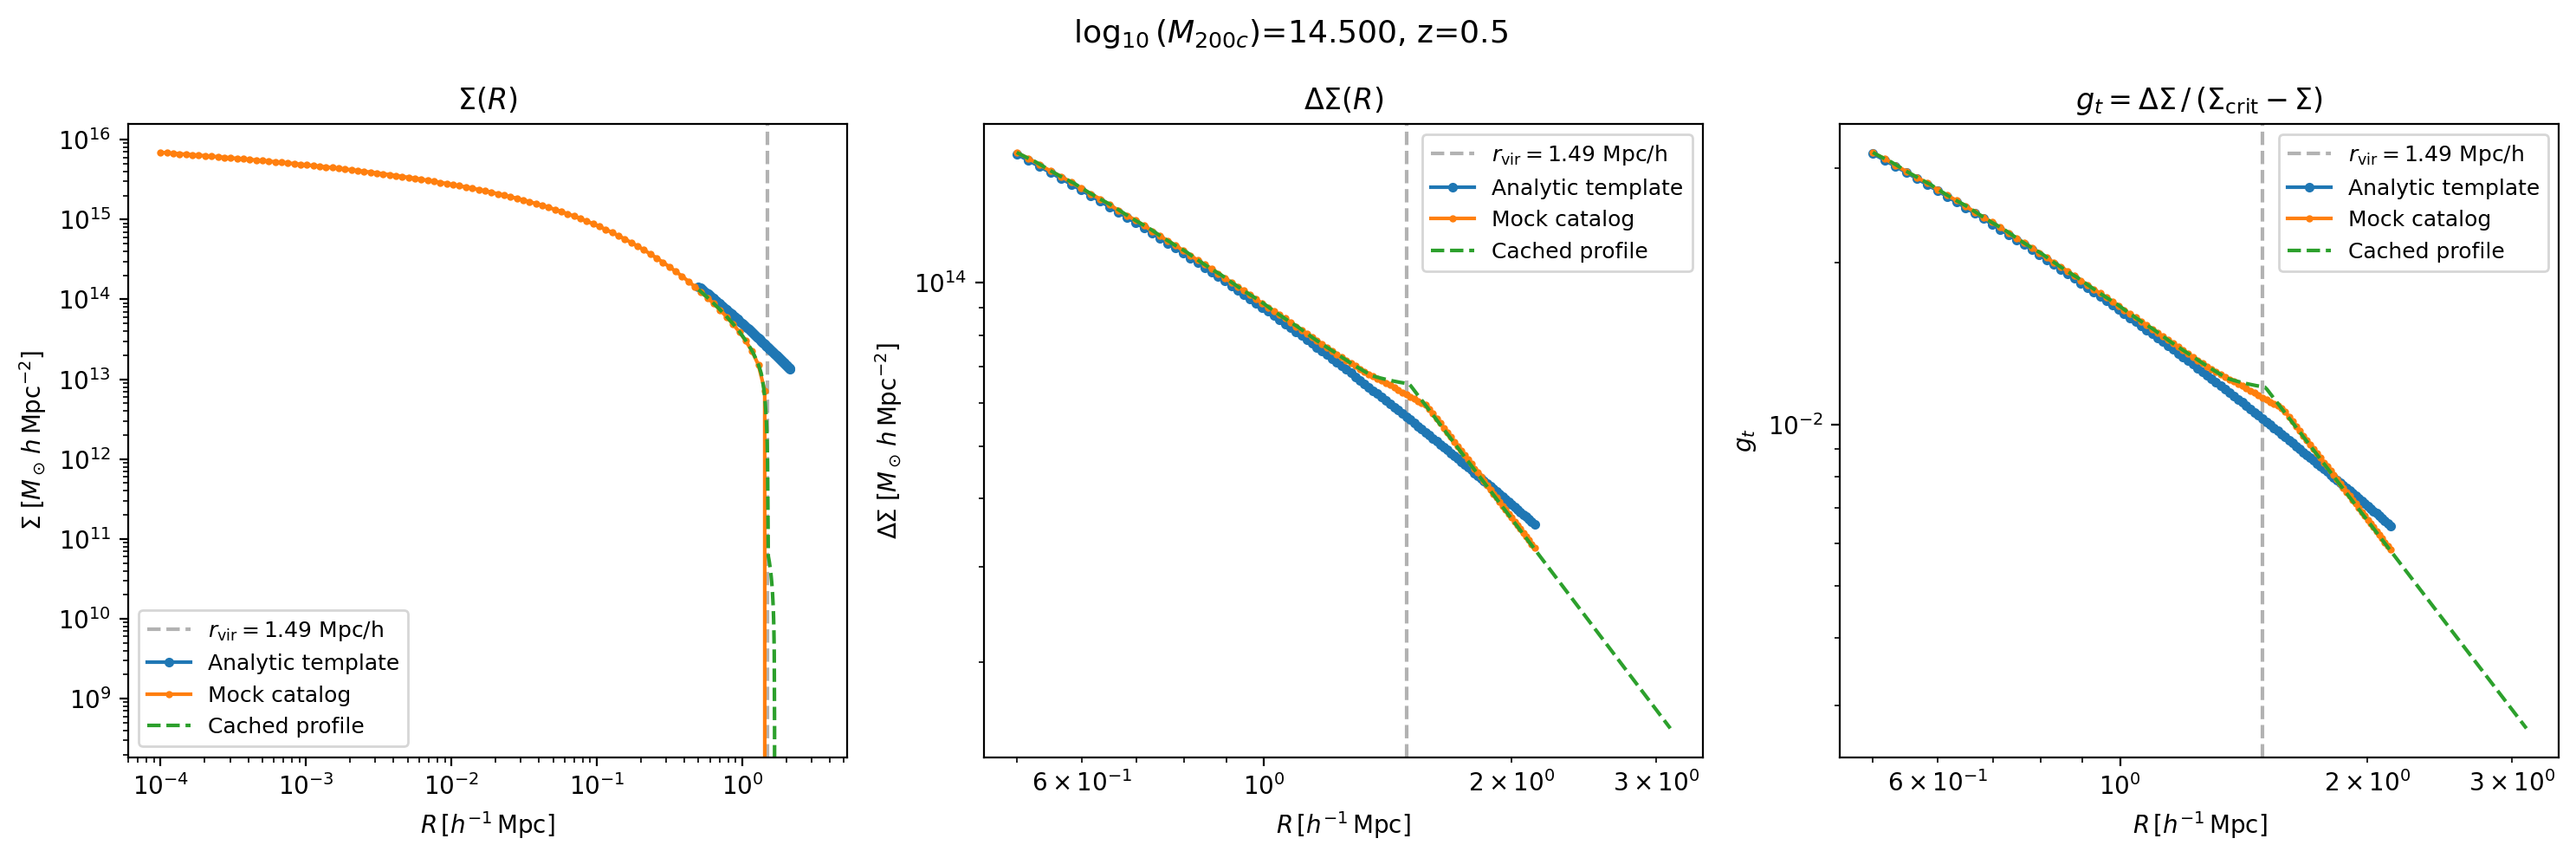

In [50]:
from wl_likelihoods import gt_nfw_from_profile
import matplotlib.pyplot as plt

z     = 0.5
M     = 10**14.5    # Msol/h
omega_m = 0.143344

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
ln_L, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    sigma_8  = 0.825264573,
    A_sz     = -4.4585462613739830,
    alpha_sz = 1.2464541653192907,
    beta_sz  = 0.8872224822960415,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    wl_catalogue = catalogue,
    use_shear_cache = True,
    return_nc = True
)

# ── Query cosmocnc profile at (z, M) ──────────────────────────────────────
profile = nc.get_profile_params_at_clusters(
    np.array([z]),
    np.array([[np.log(M / (h_fid * 1e14))]])
)

# ── rho_crit at z ─────────────────────────────────────────────────────────
rho_crit_raw = float(np.interp(z, Z_ARR, np.asarray(nc.rho_c)))
rho_crit_h   = rho_crit_raw / h_fid**2

# ── R200c and c_200c at (z, M) ────────────────────────────────────────────
M_Msol    = M / h_fid
R200c_Mpc = (M_Msol / ((4*np.pi/3) * 200 * rho_crit_raw))**(1./3.)
r_s_Mpc   = float(profile['r_s'][0, 0])
c_200c    = R200c_Mpc / r_s_Mpc

# ── Sigma_crit at z ───────────────────────────────────────────────────────
iz_z         = np.argmin(np.abs(Z_ARR - z))
Sigma_crit_h = get_Sigma_crit_arr(omega_m)[iz_z] / h_fid

# ── Radial bins ───────────────────────────────────────────────────────────
r_min  = 0.5
r_max  = 3.2 / (1. + z)
r_bins = np.linspace(r_min, r_max, 100)

# ── Analytic prediction ───────────────────────────────────────────────────
gt_pred = gt_nfw_from_profile(
    jnp.array(r_bins), M, rho_crit_h, c_200c, Sigma_crit_h)

# ── NFW components (numpy) ────────────────────────────────────────────────
def _f_nfw_np(x):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.ones_like(x)
    lt = x < 1.; gt_mask = x > 1.
    out[lt] = np.arctanh(np.sqrt(1-x[lt]**2)) / np.sqrt(1-x[lt]**2)
    out[gt_mask] = np.arctan(np.sqrt(x[gt_mask]**2-1)) / np.sqrt(x[gt_mask]**2-1)
    return out

def _g_nfw_np(x):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    out = np.full_like(x, 1.+np.log(0.5))
    lt = x < 1.; gt_mask = x > 1.
    out[lt] = np.log(x[lt]/2) + np.arctanh(np.sqrt(1-x[lt]**2))/np.sqrt(1-x[lt]**2)
    out[gt_mask] = np.log(x[gt_mask]/2) + np.arctan(np.sqrt(x[gt_mask]**2-1))/np.sqrt(x[gt_mask]**2-1)
    return out

def nfw_components(r_bins, M, rho_crit_h, c_200c):
    r_200 = (3.*M / (4.*np.pi*200.*rho_crit_h))**(1./3.)
    r_s   = r_200 / c_200c
    g_c   = np.log(1.+c_200c) - c_200c/(1.+c_200c)
    rho_s = M / (4.*np.pi*r_s**3*g_c)
    x     = r_bins / r_s
    Sigma     = 2.*rho_s*r_s / (x**2-1.) * (1.-_f_nfw_np(x))
    Sigma_bar = 4.*rho_s*r_s / x**2 * _g_nfw_np(x)
    return Sigma, Sigma_bar - Sigma

Sigma_pred, Delta_pred = nfw_components(r_bins, M, rho_crit_h, c_200c)

# ── Mock catalogue ────────────────────────────────────────────────────────
iz_cat = np.argmin(np.abs(catalogue['Z_ARR'] - z))
iM_cat = np.argmin(np.abs(np.array(catalogue['M200c_slices'][iz_cat]) - M))

gt_true    = catalogue['shear_profiles'][iz_cat][iM_cat]
Delta_true = catalogue['DeltaSigma_profiles'][iz_cat][iM_cat]
Sigma_true = catalogue['Sigma_profiles'][iz_cat][iM_cat]
R_true     = np.linspace(0.5, 3.2/(1.+z), 100)
R_for_Sigma = np.logspace(np.log10(1e-4), np.log10(3.2/(1+z)), 100)
r_vir_h    = catalogue['Rvir_slices'][iz_cat][iM_cat]

# ── Cache ─────────────────────────────────────────────────────────────────
cache    = np.load("/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_SHEAR_LCDM_CACHE.npz")
Z_grid   = cache["Z_ARR"]
M_grid   = np.exp(cache["lnM_common"])
R_common = cache["R_proj"]      # (nR,) — single static grid, FIX 1

iz_c  = np.argmin(np.abs(Z_grid - z))

b_WL_0    = 0.0
b_WL_M    = 1.0
lnM_pivot = np.log(2e14)
logM_wl   = b_WL_0 + b_WL_M*np.log(M) - b_WL_M*lnM_pivot + lnM_pivot
M_wl      = np.exp(logM_wl)
iM_c      = np.argmin(np.abs(M_grid - M_wl))

GT_cached = cache["GT_cache"][iz_c, iM_c]   # (nR,)
DS_cached = cache["DS_cache"][iz_c, iM_c]   # (nR,)
S_cached  = cache["S_cache"][iz_c,  iM_c]   # (nR,)
# FIX 2: all three use R_common, not R_proj[iz] or R_for_Sigma
R_cache   = R_common                         # (nR,) same for GT, DS, S

# ── Three-panel plot ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=200)
fig.suptitle(fr"$\log_{{10}}(M_{{200c}})$={np.log10(M):.3f}, z={z}", fontsize=13)

kw_pred  = dict(label='Analytic template', color='C0', marker='o',  ms=3, lw=1.5)
kw_mock  = dict(label='Mock catalog',      color='C1', marker='.',  ms=4, lw=1.5)
kw_cache = dict(label='Cached profile',    color='C2', marker='',   linestyle='--', lw=1.5)

for ax in axes:
    ax.axvline(r_vir_h, color='gray', linestyle='--', alpha=0.6,
               label=fr'$r_{{\rm vir}}={r_vir_h:.2f}$ Mpc/h')

axes[0].loglog(r_bins,      Sigma_pred,  **kw_pred)
axes[0].loglog(R_for_Sigma, Sigma_true,  **kw_mock)
axes[0].loglog(R_cache,     S_cached,    **kw_cache)
axes[0].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$\Sigma\;[M_\odot\,h\,\mathrm{Mpc}^{-2}]$",
            title=r"$\Sigma(R)$")
axes[0].legend(fontsize=9)

axes[1].loglog(r_bins,  Delta_pred,  **kw_pred)
axes[1].loglog(R_true,  Delta_true,  **kw_mock)
axes[1].loglog(R_cache, DS_cached,   **kw_cache)
axes[1].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$\Delta\Sigma\;[M_\odot\,h\,\mathrm{Mpc}^{-2}]$",
            title=r"$\Delta\Sigma(R)$")
axes[1].legend(fontsize=9)

axes[2].loglog(r_bins,  np.array(gt_pred), **kw_pred)
axes[2].loglog(R_true,  gt_true,           **kw_mock)
axes[2].loglog(R_cache, GT_cached,         **kw_cache)
axes[2].set(xlabel=r"$R\,[h^{-1}\,\mathrm{Mpc}]$",
            ylabel=r"$g_t$",
            title=r"$g_t = \Delta\Sigma\,/\,(\Sigma_{\rm crit} - \Sigma)$")
axes[2].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [16]:
import numpy as np
import pandas as pd
from tqdm import tqdm

catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)
b_WL_0_grid = np.linspace(-0.2, 0.2, 8)
b_WL_M_grid = np.linspace(0.8, 1.2, 8)

print("Numeric Likelihoods")
numeric_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz=-4.4585462613739830,
            alpha_sz=1.2464541653192907,
            beta_sz=0.8872224822960415,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=True
        )
        numeric_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Analytic Likelihoods")
analytic_likelihoods = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz=-4.4585462613739830,
            alpha_sz=1.2464541653192907,
            beta_sz=0.8872224822960415,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=False
        )
        analytic_likelihoods.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Numeric Likelihoods, zmax=0.8")
numeric_likelihoods_zmax08 = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz=-4.4585462613739830,
            alpha_sz=1.2464541653192907,
            beta_sz=0.8872224822960415,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=True,
            wl_z_max = 0.8
        )
        numeric_likelihoods_zmax08.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })
print("Analytic Likelihoods, zmax=0.8")
analytic_likelihoods_zmax08 = []
for b_WL_0 in tqdm(b_WL_0_grid):
    for b_WL_M in b_WL_M_grid:
        ln_L = get_log_likelihood(
            catalogue_name=catalogue_name,
            omega_m=0.143344,
            sigma_8=0.825264573,
            A_sz=-4.4585462613739830,
            alpha_sz=1.2464541653192907,
            beta_sz=0.8872224822960415,
            b_WL_0=b_WL_0,
            b_WL_M=b_WL_M,
            wl_catalogue=catalogue,
            use_shear_cache=False,
            wl_z_max = 0.8
        )
        analytic_likelihoods_zmax08.append({
            "b_WL_0": b_WL_0,
            "b_WL_M": b_WL_M,
            "ln_L": ln_L
        })

Numeric Likelihoods


100%|██████████| 8/8 [04:06<00:00, 30.81s/it]


Analytic Likelihoods


100%|██████████| 8/8 [02:20<00:00, 17.61s/it]


Numeric Likelihoods, zmax=0.8


100%|██████████| 8/8 [04:13<00:00, 31.63s/it]


Analytic Likelihoods, zmax=0.8


100%|██████████| 8/8 [02:21<00:00, 17.74s/it]


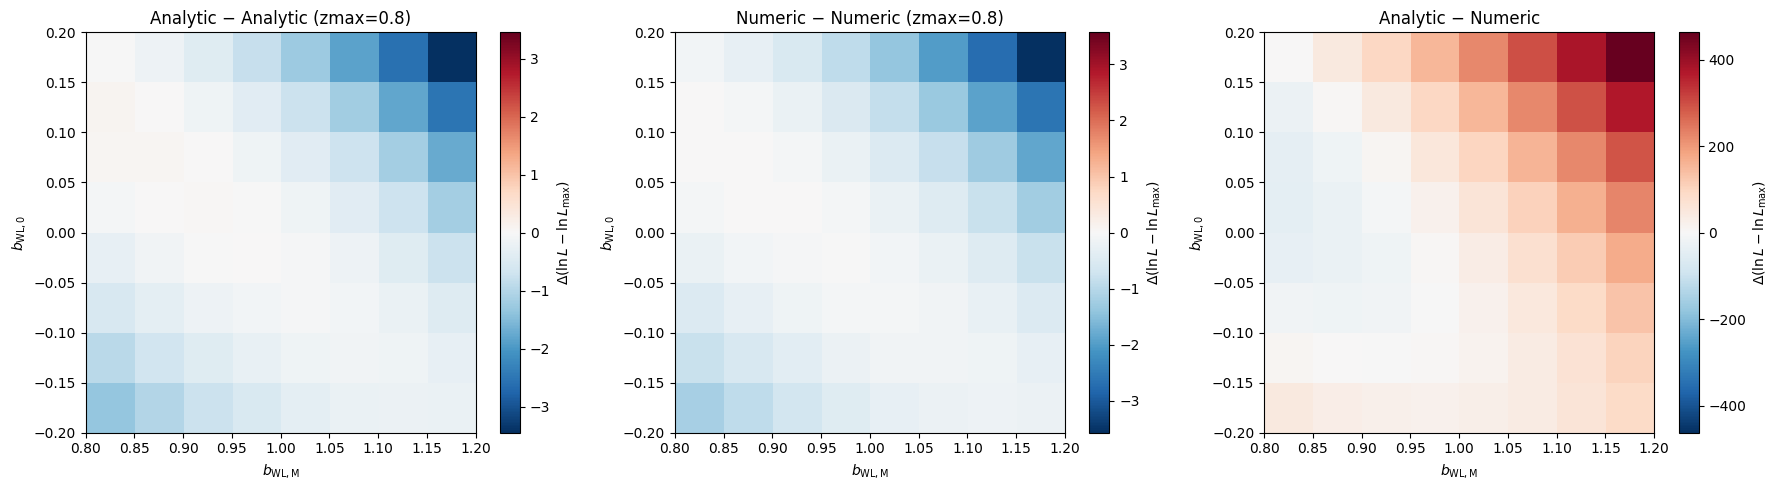

In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

analytic = pd.DataFrame(analytic_likelihoods)
analytic_z08 = pd.DataFrame(analytic_likelihoods_zmax08)
numeric = pd.DataFrame(numeric_likelihoods)
numeric_z08 = pd.DataFrame(numeric_likelihoods_zmax08)

def shape_difference(df1, df2):
    df1 = df1.copy()
    df2 = df2.copy()

    # Remove arbitrary likelihood normalization
    df1["dlnL"] = df1["ln_L"] - df1["ln_L"].max()
    df2["dlnL"] = df2["ln_L"] - df2["ln_L"].max()

    merged = df1.merge(
        df2,
        on=["b_WL_0", "b_WL_M"],
        suffixes=("_1", "_2")
    )

    merged["delta_shape"] = (
        merged["dlnL_1"] - merged["dlnL_2"]
    )

    return merged

comparisons = {
    "Analytic − Analytic (zmax=0.8)": shape_difference(
        analytic, analytic_z08
    ),
    "Numeric − Numeric (zmax=0.8)": shape_difference(
        numeric, numeric_z08
    ),
    "Analytic − Numeric": shape_difference(
        analytic, numeric
    ),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (title, df) in zip(axes, comparisons.items()):

    heatmap = df.pivot(
        index="b_WL_0",
        columns="b_WL_M",
        values="delta_shape"
    )

    vmax = np.nanmax(np.abs(heatmap.values))

    im = ax.imshow(
        heatmap.values,
        origin="lower",
        aspect="auto",
        extent=[
            heatmap.columns.min(),
            heatmap.columns.max(),
            heatmap.index.min(),
            heatmap.index.max(),
        ],
        cmap="RdBu_r",
        vmin=-vmax,
        vmax=vmax,
    )

    ax.set_title(title)
    ax.set_xlabel(r"$b_{\rm WL,M}$")
    ax.set_ylabel(r"$b_{\rm WL,0}$")

    plt.colorbar(
        im,
        ax=ax,
        label=r"$\Delta(\ln L-\ln L_{\max})$"
    )

plt.tight_layout()
plt.show()

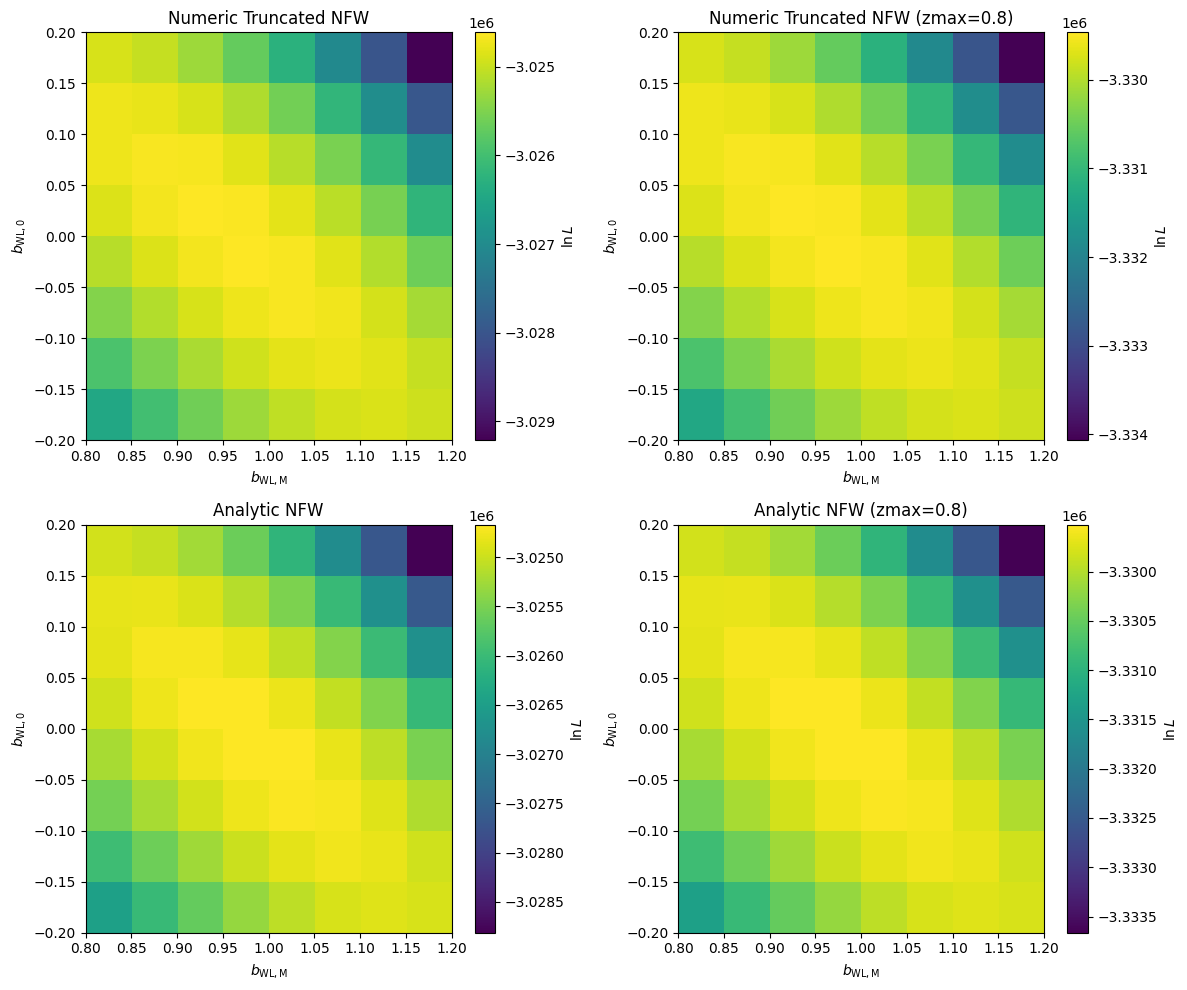

In [52]:
import pandas as pd
import matplotlib.pyplot as plt

datasets = {
    "Numeric Truncated NFW": pd.DataFrame(numeric_likelihoods),
    "Numeric Truncated NFW (zmax=0.8)": pd.DataFrame(numeric_likelihoods_zmax08),
    "Analytic NFW": pd.DataFrame(analytic_likelihoods),
    "Analytic NFW (zmax=0.8)": pd.DataFrame(analytic_likelihoods_zmax08),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (title, df) in zip(axes.flat, datasets.items()):

    heatmap = df.pivot(
        index="b_WL_0",
        columns="b_WL_M",
        values="ln_L"
    )

    im = ax.imshow(
        heatmap.values,
        origin="lower",
        aspect="auto",
        extent=[
            heatmap.columns.min(),
            heatmap.columns.max(),
            heatmap.index.min(),
            heatmap.index.max(),
        ],
    )

    ax.set_title(title)
    ax.set_xlabel(r"$b_{\rm WL,M}$")
    ax.set_ylabel(r"$b_{\rm WL,0}$")

    plt.colorbar(im, ax=ax, label=r"$\ln L$")

plt.tight_layout()
plt.show()

###### Fiducial Params

Total clusters: 26303
z range: 0.025 – 1.451

Stage 1: Fit A, alpha using z < 0.15 clusters
  Using 3306 low-z clusters
  Grid best: A=-4.500, alpha=1.150, obj=119.16
  Fit:  A=-4.420014, alpha=1.206993

  Residuals (all z, beta=0):
    z=[0.0,0.2]: mean=-0.0006, std=0.0227  (N=5541)
    z=[0.2,0.5]: mean=-0.0701, std=0.0498  (N=14384)
    z=[0.5,0.8]: mean=-0.2360, std=0.0597  (N=5449)
    z=[0.8,1.2]: mean=-0.4393, std=0.0673  (N=907)
    z=[1.2,2.0]: mean=-0.6674, std=0.0399  (N=22)

Stage 2: Fit beta from residuals vs ln(E_z)
  Linear regression: beta = -0.917820, intercept = 0.083648
  A corrected for intercept: -4.420014 - 0.083648 = -4.503662
  Nelder-Mead beta:  1.316410

Stage 3: Joint polish of all three parameters
Optimization terminated successfully.
         Current function value: 21.299134
         Iterations: 111
         Function evaluations: 209

  Final:  A=-4.458546, alpha=1.246454, beta=0.887222

Final residuals (q_pred - q_true) / q_true:
  Mean:    +0.00040  (wan

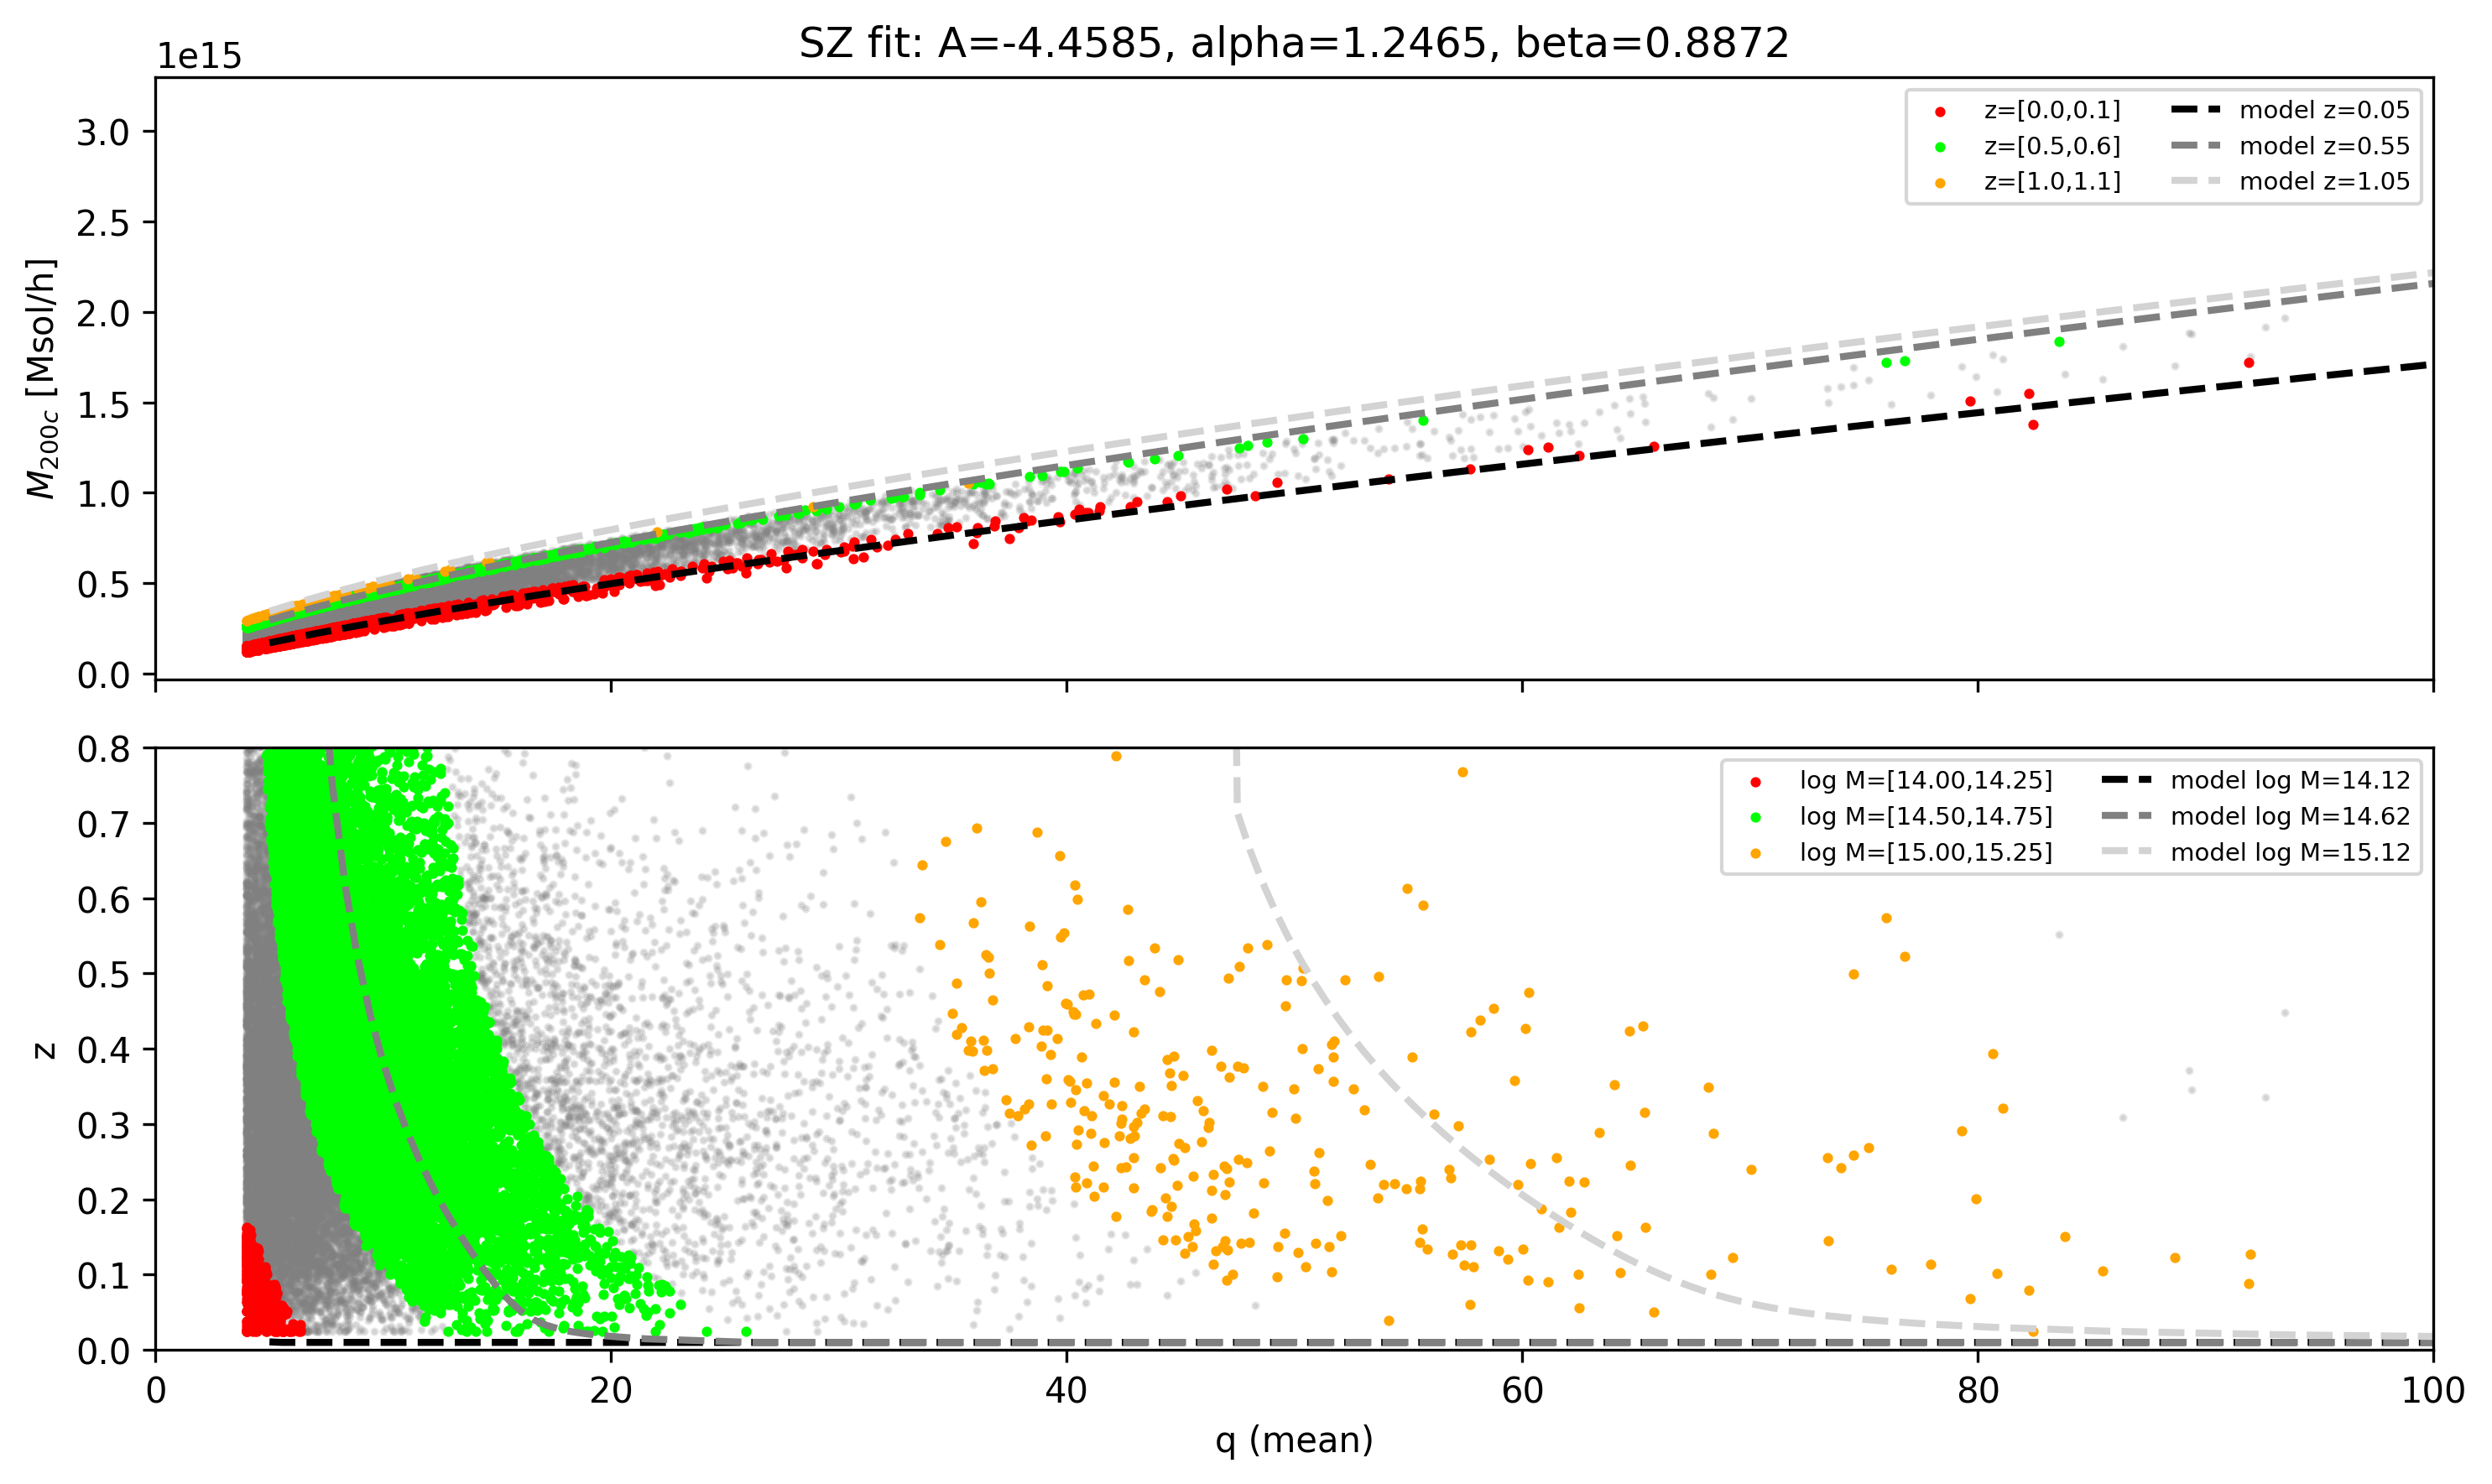


FIDUCIAL SZ PARAMETERS
  A_szifi     = -4.4585462613739830
  alpha_szifi = 1.2464541653192907
  beta_szifi  = 0.8872224822960415
  bias_sz     = 0.8  (fixed)
  dof         = 0.0  (fixed)


In [46]:
import pickle
import numpy as np
from scipy.optimize import minimize
from astropy.cosmology import FlatLambdaCDM
import matplotlib.pyplot as plt

# ── paths and constants ───────────────────────────────────────────────────────
CATALOGUE_PATH = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"
NOISE_FILE     = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/data/so_sim_sz_mf_noise.npy"

h_fid   = 0.68
omega_m = 0.143344
H0      = h_fid * 100.
bias_sz = 0.8
dof     = 0.0
Z_MAX_STAGE1 = 0.15   # use only low-z clusters for Stage 1

# ── load data ─────────────────────────────────────────────────────────────────
with open(CATALOGUE_PATH, "rb") as f:
    catalogue = pickle.load(f)

cosmo = FlatLambdaCDM(H0=H0, Om0=omega_m/h_fid**2)

theta_500_vec, sigma_sz_vec = np.load(NOISE_FILE)
theta_500_vec *= 180. * 60. / np.pi   # rad -> arcmin
sigma_sz_poly  = np.polyfit(np.log(theta_500_vec), np.log(sigma_sz_vec), deg=3)

z_cl   = catalogue['z']
M_h    = catalogue['M200c_true']    # Msol/h
q_cl   = catalogue['q_mean']
M_Msol = M_h / h_fid               # Msol (cosmocnc internal units)
E_z    = cosmo.efunc(z_cl)
D_A    = cosmo.angular_diameter_distance(z_cl).value   # Mpc
h70    = H0 / 70.

print(f"Total clusters: {len(z_cl)}")
print(f"z range: {z_cl.min():.3f} – {z_cl.max():.3f}")

# ── forward model ─────────────────────────────────────────────────────────────
def compute_q_all(A, alpha, beta, mask=None):
    """Vectorised q prediction for all (or masked) clusters."""
    M  = M_Msol  if mask is None else M_Msol[mask]
    Ez = E_z     if mask is None else E_z[mask]
    DA = D_A     if mask is None else D_A[mask]

    x0 = np.log(M / 1e14)

    prefactor_logy0 = np.log(
        10.**A * Ez**beta
        * (bias_sz/3. * h70)**alpha / np.sqrt(h70))

    log_y0 = x0 * alpha + prefactor_logy0

    prefactor_theta = (6.997 * (H0/70.)**(-2./3.)
                       * (bias_sz/3.)**(1./3.)
                       * Ez**(-2./3.) * (500./DA))

    log_theta_500 = np.log(prefactor_theta) + x0/3.
    log_sigma_sz  = np.polyval(sigma_sz_poly, log_theta_500)

    x1 = log_y0 - log_sigma_sz
    return np.sqrt(np.exp(x1)**2 + dof)


# ── Stage 1: fit A and alpha at low z (beta has negligible effect) ────────────
print()
print("="*60)
print(f"Stage 1: Fit A, alpha using z < {Z_MAX_STAGE1} clusters")
print("="*60)

mask1 = (z_cl < Z_MAX_STAGE1)
print(f"  Using {mask1.sum()} low-z clusters")

def obj_stage1(params):
    A, alpha = params
    q_pred = compute_q_all(A, alpha, beta=0.0, mask=mask1)
    resid  = np.log(q_pred) - np.log(q_cl[mask1])
    return np.sum(resid**2)

# Grid search for starting point
best_obj, best_x0 = np.inf, None
for A in np.linspace(-6., -2., 9):
    for alpha in np.linspace(0.3, 2.0, 9):
        try:
            obj = obj_stage1([A, alpha])
            if obj < best_obj:
                best_obj, best_x0 = obj, [A, alpha]
        except Exception:
            pass
print(f"  Grid best: A={best_x0[0]:.3f}, alpha={best_x0[1]:.3f}, obj={best_obj:.2f}")

result1 = minimize(obj_stage1, best_x0, method='Nelder-Mead',
                   options={'maxiter':5000, 'xatol':1e-7, 'fatol':1e-6,
                            'disp':False, 'adaptive':True})
A_fit, alpha_fit = result1.x
print(f"  Fit:  A={A_fit:.6f}, alpha={alpha_fit:.6f}")

# Residuals from Stage 1 fit across ALL clusters (beta=0)
q_pred1 = compute_q_all(A_fit, alpha_fit, beta=0.0)
resid1  = np.log(q_pred1) - np.log(q_cl)   # (n_cl,)

print(f"\n  Residuals (all z, beta=0):")
for zlo, zhi in [(0.0,0.2),(0.2,0.5),(0.5,0.8),(0.8,1.2),(1.2,2.0)]:
    m = (z_cl > zlo) & (z_cl < zhi)
    if m.sum() == 0: continue
    print(f"    z=[{zlo},{zhi}]: mean={resid1[m].mean():+.4f}, std={resid1[m].std():.4f}  (N={m.sum()})")


# ── Stage 2: fit beta from z-dependent residuals ──────────────────────────────
print()
print("="*60)
print("Stage 2: Fit beta from residuals vs ln(E_z)")
print("="*60)

# resid = ln(q_pred_beta0) - ln(q_true)
#       = beta * ln(E_z) + noise   (since prefactor_logy0 = ... + beta*ln(E_z))
# So beta = slope of resid vs ln(E_z)

ln_Ez_all = np.log(E_z)

# Linear regression: resid ~ beta * ln(E_z) + intercept
# intercept should be ~0 if A was fitted correctly at low z
coeffs = np.polyfit(ln_Ez_all, resid1, 1)
beta_linreg = coeffs[0]
intercept   = coeffs[1]
print(f"  Linear regression: beta = {beta_linreg:.6f}, intercept = {intercept:.6f}")

# Absorb intercept into A (shifts the overall normalisation)
A_corrected = A_fit - intercept
print(f"  A corrected for intercept: {A_fit:.6f} - {intercept:.6f} = {A_corrected:.6f}")

# Refine beta with Nelder-Mead on ALL clusters with A_corrected fixed
def obj_stage2(params):
    beta, = params
    q_pred = compute_q_all(A_corrected, alpha_fit, beta)
    resid  = np.log(q_pred) - np.log(q_cl)
    return np.sum(resid**2)

result2 = minimize(obj_stage2, [beta_linreg], method='Nelder-Mead',
                   options={'maxiter':2000, 'xatol':1e-7, 'fatol':1e-6,
                            'disp':False})
beta_fit = result2.x[0]
print(f"  Nelder-Mead beta:  {beta_fit:.6f}")


# ── Stage 3: joint refinement (optional polish) ───────────────────────────────
print()
print("="*60)
print("Stage 3: Joint polish of all three parameters")
print("="*60)

def obj_all(params):
    A, alpha, beta = params
    q_pred = compute_q_all(A, alpha, beta)
    resid  = np.log(q_pred) - np.log(q_cl)
    return np.sum(resid**2)

result3 = minimize(obj_all, [A_corrected, alpha_fit, beta_fit],
                   method='Nelder-Mead',
                   options={'maxiter':10000, 'xatol':1e-7, 'fatol':1e-4,
                            'disp':True, 'adaptive':True})
A_final, alpha_final, beta_final = result3.x

print(f"\n  Final:  A={A_final:.6f}, alpha={alpha_final:.6f}, beta={beta_final:.6f}")

# ── Quality check ─────────────────────────────────────────────────────────────
q_pred_final = compute_q_all(A_final, alpha_final, beta_final)
resid_final  = (q_pred_final - q_cl) / q_cl

print(f"\nFinal residuals (q_pred - q_true) / q_true:")
print(f"  Mean:    {resid_final.mean():+.5f}  (want 0)")
print(f"  Std:     {resid_final.std():.5f}")
print(f"  Max |r|: {np.abs(resid_final).max():.5f}")
print()
print("Per redshift bin:")
for zlo, zhi in [(0.0,0.2),(0.2,0.5),(0.5,0.8),(0.8,1.2),(1.2,2.0)]:
    m = (z_cl > zlo) & (z_cl < zhi)
    if m.sum() == 0: continue
    print(f"  z=[{zlo},{zhi}]: mean={resid_final[m].mean():+.5f}, "
          f"std={resid_final[m].std():.5f}  (N={m.sum()})")


# ── Diagnostic plot ────────────────────────────────────────────────────────────
def invert_q_to_M(q_vals, z_val, A, alpha, beta, M_lo=1e13, M_hi=1e16, n=500):
    M_grid = np.logspace(np.log10(M_lo), np.log10(M_hi), n)
    q_grid = compute_q_all(A, alpha, beta,
                            mask=None)   # can't use mask trick here
    # recompute for single z
    M_s  = M_grid / h_fid
    Ez_s = cosmo.efunc(z_val)
    DA_s = cosmo.angular_diameter_distance(z_val).value
    x0   = np.log(M_s / 1e14)
    pref = np.log(10.**A * Ez_s**beta * (bias_sz/3.*h70)**alpha / np.sqrt(h70))
    logy0 = x0*alpha + pref
    pt    = 6.997*(H0/70.)**(-2./3.)*(bias_sz/3.)**(1./3.)*Ez_s**(-2./3.)*(500./DA_s)
    ls    = np.polyval(sigma_sz_poly, np.log(pt) + x0/3.)
    q_g   = np.sqrt(np.exp(logy0 - ls)**2 + dof)
    return np.interp(q_vals, q_g, M_grid)

def invert_q_to_z(q_vals, M_h_val, A, alpha, beta, z_lo=0.01, z_hi=1.99, n=400):
    z_grid = np.linspace(z_lo, z_hi, n)
    q_g = []
    for z in z_grid:
        M_s  = M_h_val / h_fid
        Ez_s = cosmo.efunc(z)
        DA_s = cosmo.angular_diameter_distance(z).value
        x0   = np.log(M_s / 1e14)
        pref = np.log(10.**A * Ez_s**beta * (bias_sz/3.*h70)**alpha / np.sqrt(h70))
        pt   = 6.997*(H0/70.)**(-2./3.)*(bias_sz/3.)**(1./3.)*Ez_s**(-2./3.)*(500./DA_s)
        ls   = np.polyval(sigma_sz_poly, np.log(pt) + x0/3.)
        q_g.append(np.sqrt(np.exp(x0*alpha + pref - ls)**2 + dof))
    q_g = np.array(q_g)

    # ── Keep only the monotonically decreasing branch ─────────────────────
    # Find the peak of q(z) and use only z > z_peak (decreasing branch)
    i_peak = np.argmax(q_g)
    z_mono = z_grid[i_peak:]
    q_mono = q_g[i_peak:]

    # q_mono is now decreasing, so reverse for np.interp (needs ascending xp)
    return np.interp(q_vals, q_mono[::-1], z_mono[::-1],
                     left=z_mono[-1], right=z_mono[0])

q_line  = np.linspace(5, 170, 300)
z_plot  = [0.05, 0.55, 1.05]
M_plot  = [10**14.125, 10**14.625, 10**15.125]
colours = ['black', 'gray', 'lightgray']

M_lines = [invert_q_to_M(q_line, z, A_final, alpha_final, beta_final) for z in z_plot]
z_lines = [invert_q_to_z(q_line, M, A_final, alpha_final, beta_final) for M in M_plot]

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), dpi=300, sharex=True)

ax0.scatter(catalogue['q_mean'], catalogue['M200c_true'], s=2, alpha=0.2, color='gray')
for (zmin, zmax), c in [((0.0,0.1),'red'),((0.5,0.6),'lime'),((1.0,1.1),'orange')]:
    mask = (z_cl > zmin) & (z_cl < zmax)
    ax0.scatter(q_cl[mask], M_h[mask], c=c, s=15, marker='.', label=f'z=[{zmin},{zmax}]')
for M_line, z_val, c in zip(M_lines, z_plot, colours):
    ax0.plot(q_line, M_line, color=c, lw=2, ls='--', label=f'model z={z_val}')
ax0.legend(fontsize=7, ncol=2)
ax0.set_ylabel(r"$M_{200c}$ [Msol/h]")
ax0.set_title(f"SZ fit: A={A_final:.4f}, alpha={alpha_final:.4f}, beta={beta_final:.4f}")

ax1.scatter(catalogue['q_mean'], z_cl, s=2, alpha=0.2, color='gray')
for (Mlo, Mhi), c in [((1e14,10**14.25),'red'),((10**14.5,10**14.75),'lime'),((1e15,10**15.25),'orange')]:
    mask = (M_h > Mlo) & (M_h < Mhi)
    ax1.scatter(q_cl[mask], z_cl[mask], c=c, s=15, marker='.',
                label=fr'log M=[{np.log10(Mlo):.2f},{np.log10(Mhi):.2f}]')
for z_line, M_mid, c in zip(z_lines, M_plot, colours):
    ax1.plot(q_line, z_line, color=c, lw=2, ls='--',
             label=f'model log M={np.log10(M_mid):.2f}')
ax1.legend(fontsize=7, ncol=2)
ax1.set_ylabel("z")
ax1.set_ylim(0,0.8)
ax1.set_xlim(0,100)
ax1.set_xlabel("q (mean)")
plt.tight_layout()
plt.show()

print()
print("="*60)
print("FIDUCIAL SZ PARAMETERS")
print("="*60)
print(f"  A_szifi     = {A_final:.16f}")
print(f"  alpha_szifi = {alpha_final:.16f}")
print(f"  beta_szifi  = {beta_final:.16f}")
print(f"  bias_sz     = {bias_sz}  (fixed)")
print(f"  dof         = {dof}  (fixed)")

In [47]:
# Run combined SZ + WL likelihood at truth values
ln_L, nc = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    sigma_8  = 0.825264573,
    A_sz     = A_final,        # from fit_sz_two_stage.py
    alpha_sz = alpha_final,
    beta_sz  = beta_final,
    b_WL_0   = 0.0,
    b_WL_M   = 1.0,
    wl_catalogue = catalogue,
    use_shear_cache = True,
    return_nc = True
)

# Check mass ratios
lnM_arr = np.asarray(nc.bc_lnM_array)
cpdf    = np.asarray(nc.bc_cpdf_array)
lnM_peaks = lnM_arr[np.arange(len(nc.bc_cluster_indices)),
                     np.argmax(cpdf, axis=1)]
M_sz = np.exp(lnM_peaks) * 1e14 * h_fid
M_true = catalogue['M200c_true'][nc.bc_cluster_indices]
print(f"Mean M_SZ / M_true = {np.mean(M_sz/M_true):.4f}")

Mean M_SZ / M_true = 1.0472


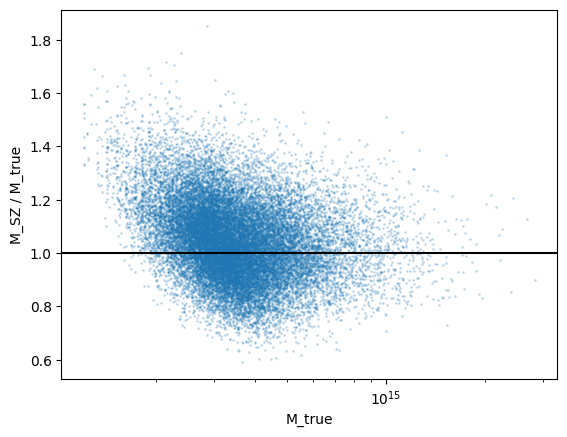

In [48]:
ratio = M_sz/M_true
plt.scatter(M_true, ratio, s=1, alpha=0.2)
plt.xscale('log')
plt.axhline(1.0, color='k')
plt.xlabel('M_true')
plt.ylabel('M_SZ / M_true')
plt.show()